# Wind VISION — PhysicsNeMo 2.2.2 Day-1 integration

**Tuesday deliverable, not a completed published-model reproduction.**

This notebook deliberately **does not reinstall PhysicsNeMo, reclone NASA, overwrite local experimental files, or use the test HDF5**. It assumes the already-established Colab L4 runtime, the pinned NASA checkout, the verified snapshot, and Drive mounted from the previous session. If you start a fresh ephemeral Colab runtime, restore those prerequisites first.

The native PhysicsNeMo VAE and flow classes preserve the NASA model architecture, full VAE objective (reconstruction + KL + coherence), and the latent flow-matching training objective. A 16-step flow pilot proves functional training/generation only; generated statistics are **not** quality validated. The comparison is same-L4, same-objective PyTorch against the native PhysicsNeMo integration and is **not guaranteed** to meet 2×. Model-parity results are logged before the benchmark.

**Security:** only the SHA-256-verified, previously trusted Lightning VAE checkpoint is deserialized with `weights_only=False`. Other arbitrary checkpoints must not be loaded this way. Original NASA repository is not edited.

In [1]:

# CELL A — Environment verification
import sys, subprocess, importlib.metadata, json
from pathlib import Path

ROOT = Path("/content")
DRIVE = Path("/content/drive/MyDrive")
REPO = ROOT / "nasa_clfm_reference"
SNAP = ROOT / "clfm_snapshot"
SCRIPT = ROOT / "wind_vision_physicsnemo_day1.py"
OUT = DRIVE / "CLFM_Research_Results/physicsnemo_day1"

OUT.mkdir(parents=True, exist_ok=True)

assert SCRIPT.is_file(), (
    "Run the existing %%writefile source cell first."
)
assert (REPO / ".git").exists(), (
    "Run the already-successful recovery cell."
)
assert (SNAP / "data/wind/wind_train_data.hdf5").exists()
assert (SNAP / "results/control_reference_vae_resume_epoch10_cpu64_v2/checkpoints/epoch-epoch=0009-step=12500.ckpt").exists()

try:
    installed = importlib.metadata.version("nvidia-physicsnemo")
except importlib.metadata.PackageNotFoundError:
    installed = None

if installed != "2.2.2":
    print("Restoring PhysicsNeMo 2.2.2...")
    subprocess.run([
        sys.executable, "-m", "pip", "install",
        "nvidia-physicsnemo==2.2.2",
        "lightning>=2.5,<3",
        "einops>=0.8.1",
        "h5py>=3.15.1"
    ], check=True)

import torch
import physicsnemo
import lightning
import h5py
import einops

from physicsnemo.core.module import Module
from physicsnemo.core.meta import ModelMetaData
from physicsnemo.utils.checkpoint import (
    save_checkpoint, load_checkpoint
)

assert torch.cuda.is_available(), (
    "Select an NVIDIA GPU in Colab runtime settings."
)
assert physicsnemo.__version__ == "2.2.2"

print("=" * 55)
print("ENVIRONMENT CHECK")
print("=" * 55)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PhysicsNeMo:", physicsnemo.__version__)
print("Lightning:", lightning.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM GiB:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
))
print("Script:", SCRIPT)
print("Output directory:", OUT)
print("=" * 55)
print("PASS — Environment ready")


ENVIRONMENT CHECK
Python: 3.13.16
PyTorch: 2.11.0+cu130
PhysicsNeMo: 2.2.2
Lightning: 2.6.6
CUDA: 13.0
GPU: NVIDIA L4
VRAM GiB: 22.03
Script: /content/wind_vision_physicsnemo_day1.py
Output directory: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1
PASS — Environment ready


In [2]:

# CELL B — Patch existing implementation safely

from pathlib import Path
import ast, hashlib, json, shutil, subprocess

script_path = Path(
    "/content/wind_vision_physicsnemo_day1.py"
)
out = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

assert script_path.exists(), "Original source cell must run first."

source = script_path.read_text()
original = source

def replace_once(old, new, label):
    global source

    if old in source:
        assert source.count(old) == 1, (
            f"Ambiguous source patch: {label}"
        )
        source = source.replace(old, new, 1)
        print("PATCHED:", label)
    elif new in source:
        print("ALREADY PATCHED:", label)
    else:
        raise RuntimeError(
            f"Source structure unexpectedly changed: {label}. "
            "Do not modify source blindly."
        )

# ------------------------------------------------------
# PATCH 1: Restore the actual NASA sparse sensor layout
# ------------------------------------------------------

replace_once(
    'dataset = dataset_class(str(train_path), sparse_sensors=False)',
    'dataset = dataset_class(str(train_path), sparse_sensors=True)',
    "40-sensor sparse wind dataset"
)

# ------------------------------------------------------
# PATCH 2: Assert checkpoint and dataset compatibility
# ------------------------------------------------------

replace_once(
    '''    sample_u, _ = dataset[0]
    model_kwargs = dict(''',
    '''    sample_u, _ = dataset[0]

    checkpoint_sensors = int(
        ref._encoder.input_layer.weight.shape[1]
    )
    dataset_sensors = int(sample_u.shape[0])

    assert checkpoint_sensors == dataset_sensors == 40, (
        f"Sparse-sensor mismatch: checkpoint={checkpoint_sensors}, "
        f"dataset={dataset_sensors}"
    )

    expected_indices = torch.tensor(
        [*range(0, 10), *range(30, 40),
         *range(60, 70), *range(90, 100)]
    )

    assert torch.equal(
        dataset.sensor_idx.cpu(), expected_indices
    ), "Unexpected sparse-sensor indices"

    print(
        f"Verified matching sparse sensor architecture: "
        f"{dataset_sensors} sensors",
        flush=True
    )

    model_kwargs = dict(''',
    "checkpoint/data channel and sensor-index verification"
)

# ------------------------------------------------------
# PATCH 3: Add a separately executable flow phase
# ------------------------------------------------------

replace_once(
    'parser.add_argument("--phase", choices=["vae", "all"], default="all")',
    'parser.add_argument("--phase", choices=["vae", "flow", "all"], default="all")',
    "separate flow phase"
)

# ------------------------------------------------------
# PATCH 4: Flow-only execution without repeated benchmark
# ------------------------------------------------------

replace_once(
    '''    assert p_ref == p_nemo, (p_ref, p_nemo)
    batch_cpu = next(iter(DataLoader(dataset, batch_size=args.batch_size,''',
    '''    assert p_ref == p_nemo, (p_ref, p_nemo)

    if args.phase == "flow":
        parity_path = OUT_ROOT / "01_full_objective_parity.json"

        if (
            not parity_path.exists()
            or not json.loads(
                parity_path.read_text()
            ).get("parity_pass")
        ):
            raise RuntimeError(
                "Complete --phase vae successfully before --phase flow"
            )

        print(
            "Starting paired latent flow pilot; "
            "VAE benchmark will not be repeated",
            flush=True
        )

        flow_metrics = train_short_flow(
            nemo, dataset, OUT_ROOT, args
        )

        save_json(
            OUT_ROOT / "04_flow_only_summary.json",
            {
                "vae_checkpoint_sha256": TRUSTED_CHECKPOINT_SHA,
                "reference_commit": PINNED_GIT_SHA,
                "sparse_sensors": True,
                "short_flow": flow_metrics,
            }
        )

        print("FLOW-ONLY PILOT COMPLETED", flush=True)
        return

    batch_cpu = next(iter(DataLoader(dataset, batch_size=args.batch_size,''',
    "flow-only execution branch"
)

# ------------------------------------------------------
# Validate, install patch, and persist to Google Drive
# ------------------------------------------------------

ast.parse(source)

if source != original:
    backup = script_path.with_suffix(".before_sparse_fix.py")
    if not backup.exists():
        backup.write_text(original)
    script_path.write_text(source)

# Confirm Python syntax
subprocess.run(
    ["python", "-m", "py_compile", str(script_path)],
    check=True
)

persisted_script = out / "wind_vision_physicsnemo_day1_patched.py"
shutil.copy2(script_path, persisted_script)

digest = hashlib.sha256(
    script_path.read_bytes()
).hexdigest()

patch_record = {
    "source_sha256": digest,
    "reference_commit": "921e666c8d6060ae13bfd901dcc7f74f819d0eea",
    "checkpoint_encoder_channels": 40,
    "sparse_sensors": True,
    "sensor_indices": [
        *range(0, 10),
        *range(30, 40),
        *range(60, 70),
        *range(90, 100)
    ],
    "independent_test_data_used": False,
    "separate_flow_phase": True
}

(out / "sparse_sensor_patch_manifest.json").write_text(
    json.dumps(patch_record, indent=2)
)

print("=" * 55)
print("PATCH VALIDATION COMPLETE")
print("=" * 55)
print("40-channel sparse encoder configured")
print("Dataset indices verified by runtime assertion")
print("Separate --phase flow enabled")
print("Python syntax check passed")
print("Patched script saved to Drive")
print("Source SHA256:", digest)
print("=" * 55)
print("READY FOR FULL-OBJECTIVE PARITY")


ALREADY PATCHED: 40-sensor sparse wind dataset
ALREADY PATCHED: checkpoint/data channel and sensor-index verification
ALREADY PATCHED: separate flow phase
ALREADY PATCHED: flow-only execution branch
PATCH VALIDATION COMPLETE
40-channel sparse encoder configured
Dataset indices verified by runtime assertion
Separate --phase flow enabled
Python syntax check passed
Patched script saved to Drive
Source SHA256: e1907525452834c13ef1840d810b45846136088bda9ee0a447530be35468d405
READY FOR FULL-OBJECTIVE PARITY


In [3]:

# CELL B2 — Fix float64/float32 mismatch

from pathlib import Path
import ast
import hashlib
import shutil

SCRIPT = Path("/content/wind_vision_physicsnemo_day1.py")
OUT = Path("/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1")

assert SCRIPT.exists(), "Run the original %%writefile cell first."
OUT.mkdir(parents=True, exist_ok=True)

source = SCRIPT.read_text()
original = source

def patch_once(old, new, label):
    global source

    if new in source:
        print("ALREADY PATCHED:", label)
        return

    count = source.count(old)
    assert count == 1, (
        f"Expected exactly one occurrence for {label}, found {count}"
    )

    source = source.replace(old, new, 1)
    print("PATCHED:", label)

# 1. Convert trusted reference VAE to float32
patch_once(
    'weights_only=False).cuda().train()',
    'weights_only=False).to(device="cuda", dtype=torch.float32).train()',
    "Reference VAE float32 conversion"
)

# 2. Explicitly align physics-loss buffers
patch_once(
    'loss_impl = loss_impl.cuda()',
    'loss_impl = loss_impl.to(device="cuda", dtype=torch.float32)',
    "WindLoss buffer precision"
)

# 3. Explicitly align PhysicsNeMo VAE precision
patch_once(
    'nemo = PhysicsNeMoWindVAE(**model_kwargs).cuda().train()',
    'nemo = PhysicsNeMoWindVAE(**model_kwargs).to(device="cuda", dtype=torch.float32).train()',
    "PhysicsNeMo VAE float32"
)

# 4. Verify matching precision BEFORE parity
patch_once(
    '''    batch_gpu = (batch_cpu[0].cuda(), batch_cpu[1].cuda())
    parity_metrics = parity(''',
    '''    batch_gpu = (batch_cpu[0].cuda(), batch_cpu[1].cuda())

    for name, model in (
        ("NASA reference", ref),
        ("PhysicsNeMo", nemo),
    ):
        model_dtype = next(model.parameters()).dtype

        assert (
            model_dtype
            == batch_gpu[0].dtype
            == batch_gpu[1].dtype
            == torch.float32
        ), (
            f"{name} precision mismatch: "
            f"model={model_dtype}, "
            f"wind={batch_gpu[0].dtype}, "
            f"coordinates={batch_gpu[1].dtype}"
        )

        print(
            f"PRECISION CHECK PASSED: {name} / {model_dtype}",
            flush=True
        )

    parity_metrics = parity(''',
    "Pre-parity dtype verification"
)

# 5. Validate syntax before modifying the script
ast.parse(source)

# Save previous version if changes were necessary
if source != original:
    backup = OUT / "wind_vision_before_dtype_fix.py"
    if not backup.exists():
        backup.write_text(original)
    SCRIPT.write_text(source)

# Persist the new implementation
saved_script = OUT / "wind_vision_physicsnemo_day1_patched.py"
shutil.copy2(SCRIPT, saved_script)

digest = hashlib.sha256(SCRIPT.read_bytes()).hexdigest()

print("\n" + "=" * 60)
print("PRECISION PATCH COMPLETE")
print("=" * 60)
print("Reference model: float32")
print("PhysicsNeMo model: float32")
print("Wind input: float32")
print("Coordinates: float32")
print("Original checkpoint: unchanged")
print("NASA source repository: unchanged")
print("Syntax validation: PASSED")
print("SHA256:", digest)
print("Persisted script:", saved_script)
print("=" * 60)
print("READY — RERUN CELL C")


ALREADY PATCHED: Reference VAE float32 conversion
ALREADY PATCHED: WindLoss buffer precision
ALREADY PATCHED: PhysicsNeMo VAE float32
ALREADY PATCHED: Pre-parity dtype verification

PRECISION PATCH COMPLETE
Reference model: float32
PhysicsNeMo model: float32
Wind input: float32
Coordinates: float32
Original checkpoint: unchanged
NASA source repository: unchanged
Syntax validation: PASSED
SHA256: e1907525452834c13ef1840d810b45846136088bda9ee0a447530be35468d405
Persisted script: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/wind_vision_physicsnemo_day1_patched.py
READY — RERUN CELL C


In [4]:

# CELL B3 — Fix dataset coordinate precision throughout pipeline

from pathlib import Path
import ast
import shutil
import hashlib
import subprocess

SCRIPT = Path("/content/wind_vision_physicsnemo_day1.py")
OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

source = SCRIPT.read_text()

old = '    dataset = dataset_class(str(train_path), sparse_sensors=True)\n'

new = old + '''
    # Normalize coordinate dtype for the matched float32 experiment.
    # Preserve physical coordinate VALUES and sensor ordering.
    dataset.points = dataset.points.to(dtype=torch.float32)
    assert dataset.points.dtype == torch.float32
    print(
        f"Dataset coordinate precision verified: {dataset.points.dtype}",
        flush=True
    )
'''

if new in source:
    print("Coordinate precision patch already applied.")
else:
    assert source.count(old) == 1, (
        "Dataset initialization pattern not found exactly once. "
        "Inspect the source before changing it."
    )
    patched = source.replace(old, new, 1)
    ast.parse(patched)

    backup = OUT / "wind_vision_before_coordinate_fix.py"
    if not backup.exists():
        backup.write_text(source)

    SCRIPT.write_text(patched)
    print("PATCHED: float32 dataset coordinates")

subprocess.run(
    ["python", "-m", "py_compile", str(SCRIPT)],
    check=True
)

shutil.copy2(
    SCRIPT,
    OUT / "wind_vision_physicsnemo_day1_patched.py"
)

print("=" * 55)
print("COORDINATE DTYPE FIX COMPLETE")
print("=" * 55)
print("VAE weights: float32")
print("Wind samples: float32")
print("Coordinates: float32")
print("Physics loss buffers: float32")
print("Original checkpoint: unchanged")
print("NASA repository: unchanged")
print("Syntax check: PASSED")
print("Updated script saved to Google Drive")
print("SHA256:", hashlib.sha256(SCRIPT.read_bytes()).hexdigest())
print("READY TO RERUN CELL C")


Coordinate precision patch already applied.
COORDINATE DTYPE FIX COMPLETE
VAE weights: float32
Wind samples: float32
Coordinates: float32
Physics loss buffers: float32
Original checkpoint: unchanged
NASA repository: unchanged
Syntax check: PASSED
Updated script saved to Google Drive
SHA256: e1907525452834c13ef1840d810b45846136088bda9ee0a447530be35468d405
READY TO RERUN CELL C


In [5]:

# CELL C — PyTorch vs PhysicsNeMo VAE integration

import subprocess, sys, time
from pathlib import Path

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
SCRIPT = Path("/content/wind_vision_physicsnemo_day1.py")

logfile = OUT / "vae_integration_execution_v2.log"

command = [
    sys.executable, "-u", str(SCRIPT),
    "--phase", "vae",
    "--batch-size", "4",
    "--bench-steps", "8",
    "--bench-warmup", "2",
    "--seed", "20261029"
]

print("STARTING FULL-OBJECTIVE VAE EXPERIMENT")
print("Includes:")
print(" - Verified 40-sensor checkpoint compatibility")
print(" - PhysicsNeMo strict weight transfer")
print(" - Reconstruction + KL + coherence residual")
print(" - Backward gradient parity")
print(" - Full optimizer-step timing on the L4")
print(" - Native checkpoint save and restore")
print("=" * 60, flush=True)

start = time.perf_counter()

with logfile.open("w") as log:
    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()

    exit_code = process.wait()

elapsed = time.perf_counter() - start

print("\n" + "=" * 60)
print("EXIT CODE:", exit_code)
print("ELAPSED SECONDS:", round(elapsed, 2))
print("LOG SAVED:", logfile)

if exit_code != 0:
    raise RuntimeError(
        "VAE experiment failed. Copy the traceback shown above."
    )

print("VAE EXPERIMENT FINISHED")


STARTING FULL-OBJECTIVE VAE EXPERIMENT
Includes:
 - Verified 40-sensor checkpoint compatibility
 - PhysicsNeMo strict weight transfer
 - Reconstruction + KL + coherence residual
 - Backward gradient parity
 - Full optimizer-step timing on the L4
 - Native checkpoint save and restore
Loading verified, trusted pinned-reference checkpoint ...
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module

## Run: parity, optimizer benchmark, paired latent-flow pilot, independent generation

The cell runs the code in a **fresh Python process**, ensuring the pinned `clfm` checkout is imported instead of any modified modules left in Colab memory. Start with `--phase vae` if limited on GPU time, then run `--phase all` once parity and optimizer passes succeed. The notebook saves checkpoint files, JSON and PNG figures into Drive.

In [6]:

# CELL D — Results inspection

from pathlib import Path
import json

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

def read_report(name):
    path = OUT / name
    if not path.exists():
        print("MISSING:", name)
        return None
    return json.loads(path.read_text())

parity = read_report("01_full_objective_parity.json")
benchmark = read_report("02_same_l4_full_step_benchmark.json")
checkpoint = read_report("03_native_checkpoint_status.json")

print("\n" + "=" * 60)
print("1. FULL-OBJECTIVE PARITY")
print("=" * 60)

if parity is not None:
    print("PASS:", parity["parity_pass"])
    print(
        "Relative loss difference:",
        parity["relative_total_loss_difference"]
    )
    print(
        "Relative gradient difference:",
        parity["relative_full_parameter_gradient_l2_difference"]
    )
    print(
        "Gradient tensor count:",
        parity["number_of_gradient_tensors"]
    )
    print(
        "PyTorch losses:",
        parity["reference"]
    )
    print(
        "PhysicsNeMo losses:",
        parity["physicsnemo"]
    )

print("\n" + "=" * 60)
print("2. SAME-GPU PERFORMANCE")
print("=" * 60)

if benchmark is not None:
    print("GPU:", benchmark["gpu"])
    print("Batch size:", benchmark["batch_size"])
    print(
        "Measured steps:",
        benchmark["measured_steps_per_impl"]
    )
    print(
        "PyTorch median ms:",
        benchmark["pytorch"]["median_ms"]
    )
    print(
        "PhysicsNeMo median ms:",
        benchmark["physicsnemo"]["median_ms"]
    )
    print(
        "Speed ratio PyTorch / PhysicsNeMo:",
        benchmark["speedup_pytorch_over_physicsnemo"]
    )
    print(
        "2x target reached in pilot:",
        benchmark["target_2x_met_in_this_pilot"]
    )

print("\n" + "=" * 60)
print("3. CHECKPOINTING")
print("=" * 60)

if checkpoint is not None:
    print(json.dumps(checkpoint, indent=2))

print("\n" + "=" * 60)
print("VAE RESULTS REVIEW COMPLETE")



1. FULL-OBJECTIVE PARITY
PASS: True
Relative loss difference: 0.0
Relative gradient difference: 5.661857612567395e-10
Gradient tensor count: 164
PyTorch losses: {'implementation': 'pytorch', 'total': 0.0038392727728933096, 'reconstruction': 0.0028438796289265156, 'kl_unweighted': 29.54083251953125, 'residual_unweighted': 0.0965852364897728}
PhysicsNeMo losses: {'implementation': 'physicsnemo', 'total': 0.0038392727728933096, 'reconstruction': 0.0028438796289265156, 'kl_unweighted': 29.54083251953125, 'residual_unweighted': 0.0965852364897728}

2. SAME-GPU PERFORMANCE
GPU: NVIDIA L4
Batch size: 4
Measured steps: 8
PyTorch median ms: 287.68933649917017
PhysicsNeMo median ms: 287.1944734997669
Speed ratio PyTorch / PhysicsNeMo: 1.0017230937398371
2x target reached in pilot: False

3. CHECKPOINTING
{
  "attempted": true,
  "success": true,
  "restore_weights_equal": true
}

VAE RESULTS REVIEW COMPLETE


In [7]:

# CELL E — PhysicsNeMo latent flow and wind generation

import subprocess, sys, json, time
from pathlib import Path

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
SCRIPT = Path("/content/wind_vision_physicsnemo_day1.py")

parity_path = OUT / "01_full_objective_parity.json"

assert parity_path.exists(), (
    "Run VAE integration first."
)
assert json.loads(parity_path.read_text())["parity_pass"], (
    "Cannot proceed until full-objective parity passes."
)

logfile = OUT / "latent_flow_execution_v2.log"

command = [
    sys.executable, "-u", str(SCRIPT),
    "--phase", "flow",
    "--batch-size", "4",
    "--flow-steps", "32",
    "--latent-batches", "16",
    "--flow-hidden", "512",
    "--flow-layers", "5",
    "--num-generated", "4",
    "--rk-steps", "32",
    "--seed", "20261029"
]

print("STARTING PAIRED LATENT FLOW EXPERIMENT")
print("VAE: trusted epoch-ten checkpoint")
print("Sensor configuration: 40 sparse sensors")
print("Latent dimensions: 128")
print("Flow training steps: 32")
print("Generated fields: 4")
print("Sampling: fixed-step RK4")
print("=" * 60, flush=True)

start = time.perf_counter()

with logfile.open("w") as log:
    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()

    exit_code = process.wait()

print("\nEXIT CODE:", exit_code)
print(
    "ELAPSED SECONDS:",
    round(time.perf_counter() - start, 2)
)
print("LOG SAVED:", logfile)

if exit_code != 0:
    raise RuntimeError(
        "Latent flow failed. Copy the traceback above."
    )

print("FLOW TRAINING AND GENERATION COMPLETED")


STARTING PAIRED LATENT FLOW EXPERIMENT
VAE: trusted epoch-ten checkpoint
Sensor configuration: 40 sparse sensors
Latent dimensions: 128
Flow training steps: 32
Generated fields: 4
Sampling: fixed-step RK4
Loading verified, trusted pinned-reference checkpoint ...
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them u

END-TO-END PHYSICSNEMO WIND GENERATION
Training steps: 32
Latent-statistics fields: 64
Initial flow loss: 2.243784189224243
Final flow loss: 1.959037184715271
Generated shape: [4, 40, 256]
All values finite: True
Sampling solver: RK4-32 (NOT original dopri5)
Quality validated: False

Saved files:
PASS latent_flow/flow_demo_metrics.json
PASS latent_flow/short_flow_wind_demo.png
PASS latent_flow/unconditional_samples.pt
PASS latent_flow/paired_flow_state.pt

WIND FIELD VISUALIZATION


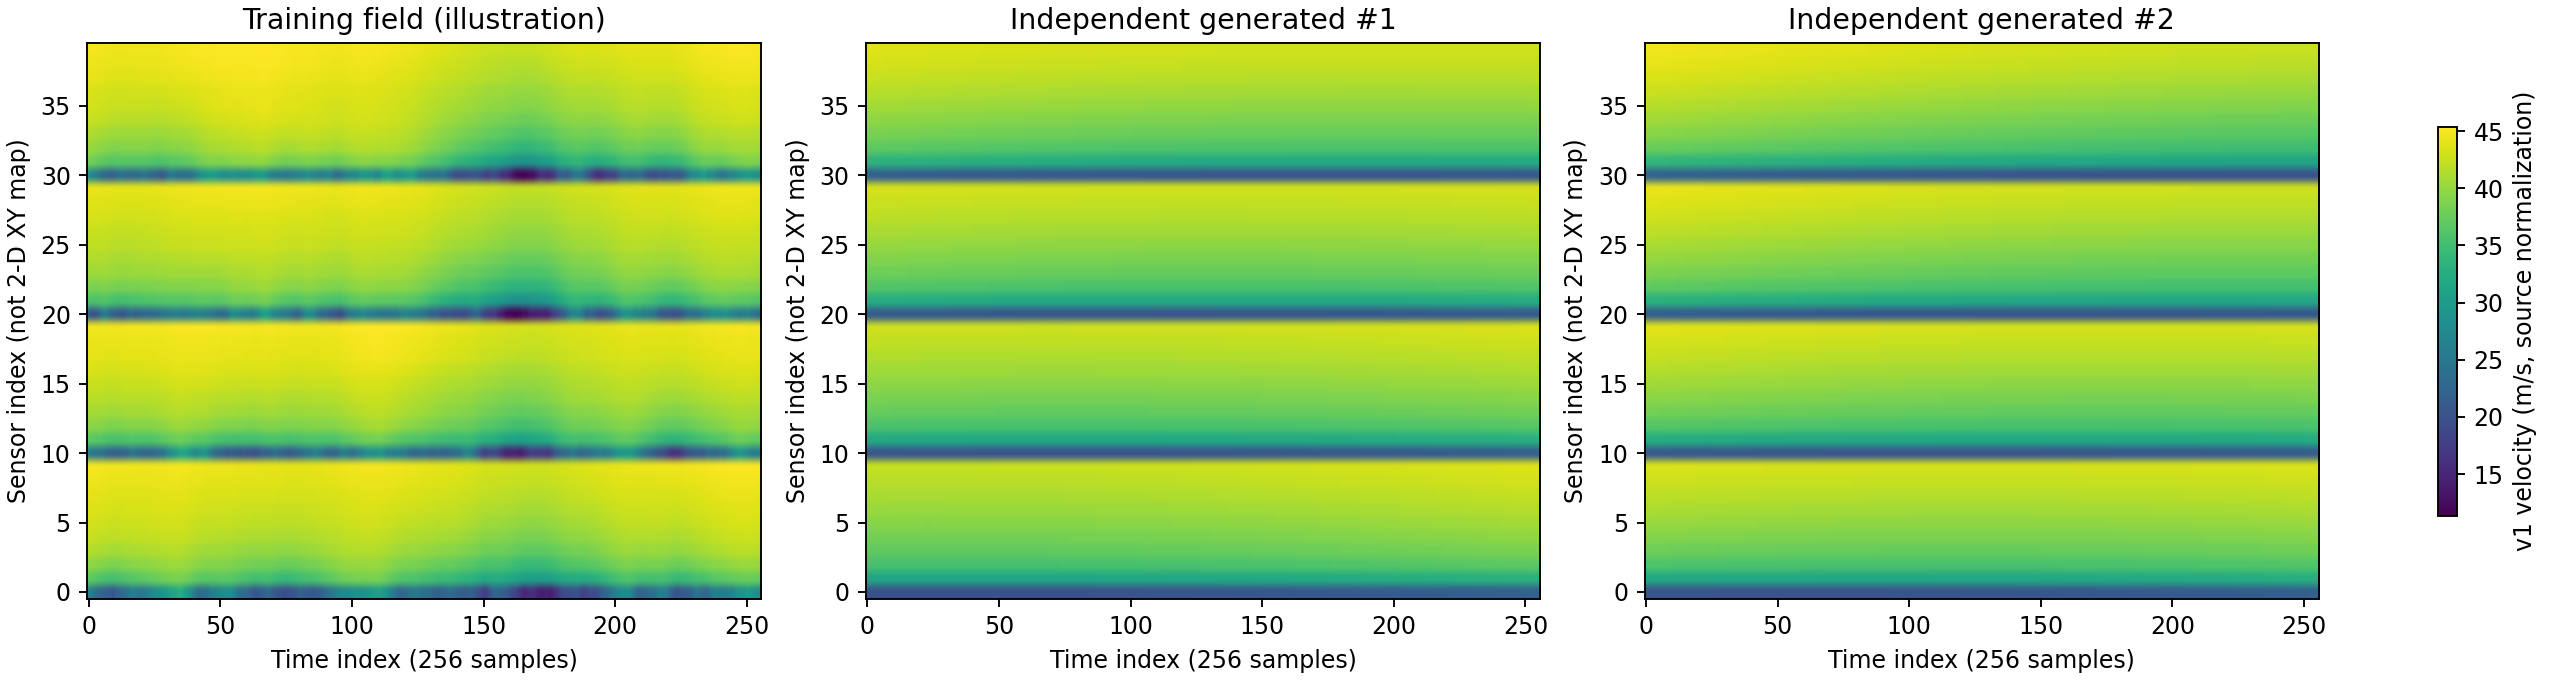


END-TO-END FUNCTIONAL DEMONSTRATION COMPLETE
Independent statistical fidelity remains unvalidated.


In [8]:

# CELL F — End-to-end generation results

import json
from pathlib import Path
from IPython.display import display, Image

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

FLOW_DIR = OUT / "latent_flow"
METRICS = FLOW_DIR / "flow_demo_metrics.json"
FIGURE = FLOW_DIR / "short_flow_wind_demo.png"
SAMPLES = FLOW_DIR / "unconditional_samples.pt"
FLOW_STATE = FLOW_DIR / "paired_flow_state.pt"

assert METRICS.exists(), "No flow metrics saved."
assert FIGURE.exists(), "No flow visualization saved."

m = json.loads(METRICS.read_text())

print("=" * 60)
print("END-TO-END PHYSICSNEMO WIND GENERATION")
print("=" * 60)

print("Training steps:", m["training_steps"])
print("Latent-statistics fields:", m["latent_stats_fields"])
print("Initial flow loss:", m["loss_start"])
print("Final flow loss:", m["loss_end"])
print("Generated shape:", m["sample_shape"])
print("All values finite:", m["all_generated_finite"])
print("Sampling solver:", m["sampling_solver"])
print("Quality validated:", m["quality_validated"])

print("\nSaved files:")
for p in [METRICS, FIGURE, SAMPLES, FLOW_STATE]:
    print(
        "PASS" if p.exists() else "MISSING",
        p.relative_to(OUT)
    )

assert m["all_generated_finite"], (
    "Generated wind contains non-finite values."
)

print("\nWIND FIELD VISUALIZATION")
display(Image(filename=str(FIGURE)))

print("\nEND-TO-END FUNCTIONAL DEMONSTRATION COMPLETE")
print("Independent statistical fidelity remains unvalidated.")


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

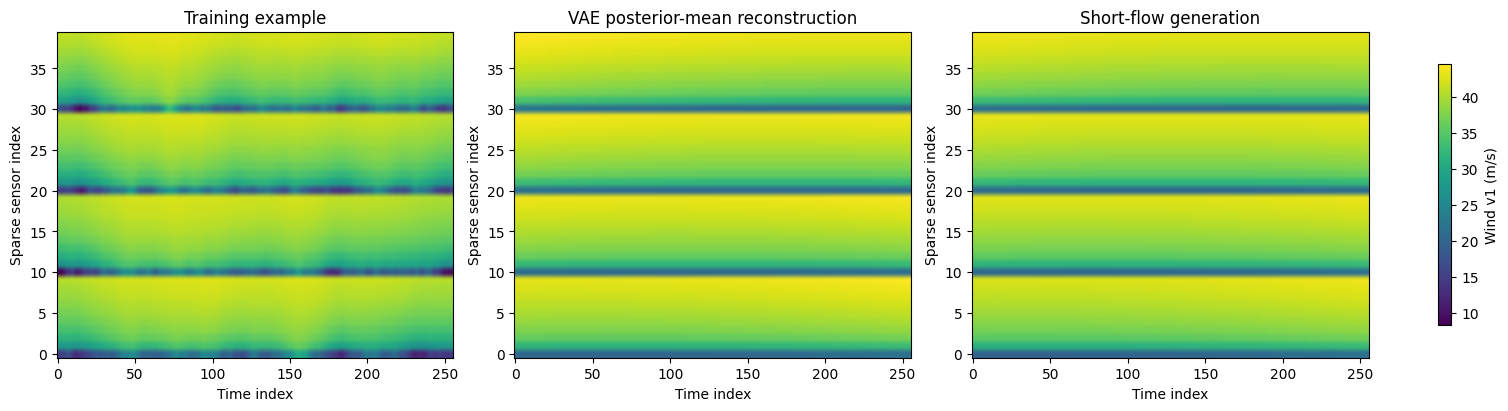


========== FIDELITY DIAGNOSTIC ==========
Generated / training temporal variance: 0.05196928612459236
Generated / training high-frequency PSD: 0.06223684025010609
Generated / training field variance: 0.010886837314078284
Posterior-mean / training temporal variance: 0.042810977414540145
Posterior-mean / training high-frequency PSD: 0.04844938751073389
Saved: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/07_training_only_fidelity_audit.json
Saved: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/07_training_vs_posterior_vs_flow.png


In [9]:

# CELL G — TRAINING-ONLY GENERATION FIDELITY AUDIT
# No retraining or new downloads.

import json, hashlib, sys
from pathlib import Path
import numpy as np
import torch, h5py
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1")
TRAIN = Path("/content/clfm_snapshot/data/wind/wind_train_data.hdf5")
CKPT = Path("/content/clfm_snapshot/results/control_reference_vae_resume_epoch10_cpu64_v2/checkpoints/epoch-epoch=0009-step=12500.ckpt")
SAMPLES = ROOT / "latent_flow/unconditional_samples.pt"

assert TRAIN.is_file() and CKPT.is_file() and SAMPLES.is_file()
assert torch.cuda.is_available()

# Locally generated tensor-only artifact
gen_data = torch.load(SAMPLES, map_location="cpu", weights_only=True)
generated = gen_data["u_normalized"].detach().float().numpy()
assert generated.shape[1:] == (40, 256)
assert np.isfinite(generated).all()

sensor_indices = np.r_[0:10, 30:40, 60:70, 90:100]
rng = np.random.default_rng(20261029)

# Sample training examples only; do not touch the test HDF5.
with h5py.File(TRAIN, "r") as f:
    keys = sorted(f["wind_samples"].keys(), key=int)
    chosen = rng.choice(len(keys), size=min(64, len(keys)), replace=False)
    raw_reference = np.stack([
        np.asarray(
            f["wind_samples"][keys[int(i)]]["v1"],
            dtype=np.float32
        )[sensor_indices]
        for i in chosen
    ])
    xyz = np.asarray(f["x_grid"], dtype=np.float32)[sensor_indices]
    times = np.asarray(f["t_grid"], dtype=np.float32).reshape(-1)

reference = (raw_reference + 2.0) / 49.0

coords = np.concatenate([
    np.broadcast_to(xyz[:, None, :], (40, 256, 3)),
    np.broadcast_to(times[None, :, None], (40, 256, 1))
], axis=-1).reshape(1, -1, 4).astype(np.float32)

def wind_stats(fields):
    a = np.asarray(fields, dtype=np.float64)
    centered = a - a.mean(axis=-1, keepdims=True)
    power = np.abs(np.fft.rfft(centered, axis=-1)) ** 2
    power = power.mean(axis=(0, 1))

    return {
        "mean_velocity_m_s": float(a.mean() * 49 - 2),
        "temporal_variance_m_s2": float(
            a.var(axis=-1).mean() * 49**2
        ),
        "between_field_variance_m_s2": float(
            a.var(axis=0).mean() * 49**2
        ),
        "low_psd_bins_1_6": float(power[1:7].mean()),
        "mid_psd_bins_7_16": float(power[7:17].mean()),
        "high_psd_bins_17_64": float(power[17:65].mean())
    }

def ratios(a, b):
    return {
        k: float(a[k] / b[k]) if abs(b[k]) > 1e-20 else None
        for k in a if k != "mean_velocity_m_s"
    }

reference_stats = wind_stats(reference)
generated_stats = wind_stats(generated)
generation_ratios = ratios(generated_stats, reference_stats)

# Verify trusted checkpoint before deserialization.
expected_hash = "b78f9e00e623ccd3b72cc3f07751de5d7f27a930e95bcabe437aada14a62eb68"
h = hashlib.sha256()
with CKPT.open("rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        h.update(chunk)
assert h.hexdigest() == expected_hash

sys.path.insert(0, "/content/nasa_clfm_reference")
from clfm.nn.vae import FunctionalVAE

vae = FunctionalVAE.load_from_checkpoint(
    str(CKPT),
    map_location="cpu",
    weights_only=False
).to(device="cuda", dtype=torch.float32).eval()

# Posterior-mean reconstructions on eight training examples
posterior_fields = []
with torch.inference_mode():
    x_gpu = torch.from_numpy(coords).cuda()

    for start in range(0, min(8, len(reference)), 2):
        u = torch.from_numpy(reference[start:start+2]).cuda()
        mu, logvar = vae.encode(u)
        prediction = vae.decode(
            mu, x_gpu.expand(len(u), -1, -1)
        ).reshape(-1, 40, 256)
        posterior_fields.append(
            prediction.float().cpu().numpy()
        )

posterior = np.concatenate(posterior_fields)
posterior_stats = wind_stats(posterior)
posterior_reference_stats = wind_stats(reference[:len(posterior)])
posterior_ratios = ratios(posterior_stats, posterior_reference_stats)

del vae
torch.cuda.empty_cache()

# Plot with shared physical units and color limits.
panels = [reference[0], posterior[0], generated[0]]
titles = [
    "Training example",
    "VAE posterior-mean reconstruction",
    "Short-flow generation"
]

fig, axs = plt.subplots(
    1, 3, figsize=(15, 4), constrained_layout=True
)
vmin = min(float(p.min()) for p in panels) * 49 - 2
vmax = max(float(p.max()) for p in panels) * 49 - 2

for ax, title, field in zip(axs, titles, panels):
    im = ax.imshow(
        field * 49 - 2,
        origin="lower",
        aspect="auto",
        vmin=vmin,
        vmax=vmax,
        cmap="viridis"
    )
    ax.set_title(title)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor index")

fig.colorbar(im, ax=axs, label="Wind v1 (m/s)", shrink=0.8)
figpath = ROOT / "07_training_vs_posterior_vs_flow.png"
fig.savefig(figpath, dpi=160)
display(fig)
plt.close(fig)

results = {
    "evaluation": "TRAINING-ONLY DIAGNOSTIC, NOT INDEPENDENT TEST",
    "n_reference": len(reference),
    "n_generated": len(generated),
    "n_posterior": len(posterior),
    "reference": reference_stats,
    "generated": generated_stats,
    "generation_to_training_ratios": generation_ratios,
    "posterior_mean": posterior_stats,
    "posterior_to_training_ratios": posterior_ratios,
    "limitations": [
        "Only four generated fields",
        "Training data is not an independent holdout",
        "Posterior-mean reconstruction is deterministic",
        "40 sparse sensors, not a full 2D spatial field"
    ]
}

jsonpath = ROOT / "07_training_only_fidelity_audit.json"
jsonpath.write_text(json.dumps(results, indent=2))

print("\n========== FIDELITY DIAGNOSTIC ==========")
print("Generated / training temporal variance:",
      generation_ratios["temporal_variance_m_s2"])
print("Generated / training high-frequency PSD:",
      generation_ratios["high_psd_bins_17_64"])
print("Generated / training field variance:",
      generation_ratios["between_field_variance_m_s2"])
print("Posterior-mean / training temporal variance:",
      posterior_ratios["temporal_variance_m_s2"])
print("Posterior-mean / training high-frequency PSD:",
      posterior_ratios["high_psd_bins_17_64"])
print("Saved:", jsonpath)
print("Saved:", figpath)


In [10]:

# ============================================================
# CELL H — GPU-VECTORIZED COHERENCE VALIDATION
# Wind VISION / NVIDIA PhysicsNeMo 2.2.2
#
# Compares:
# 1. Original NASA PyTorch VAE + original coherence constraint
# 2. PhysicsNeMo VAE + GPU-vectorized analytical target
#
# IMPORTANT:
# - Same checkpoint, weights, inputs, random seeds
# - Full loss: reconstruction + KL + coherence residual
# - Compare complete parameter gradients
# - Do NOT benchmark if gradient parity fails
# - Preserve variables for Cells I and J
# - Do NOT modify the original NASA repository
# ============================================================

import copy
import json
import sys
from pathlib import Path

import torch
from torch.utils.data import DataLoader

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
OUT.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, "/content")
sys.path.insert(0, "/content/nasa_clfm_reference")

import wind_vision_physicsnemo_day1 as w
import clfm.problems.wind as original_wind


# ============================================================
# 1. VERIFY ENVIRONMENT AND LOAD REFERENCE IMPORTS
# ============================================================

assert torch.cuda.is_available(), "NVIDIA GPU not available."

ckpt, train_path = w.assert_environment()

(
    FVAE,
    _,
    _,
    _,
    _,
    DataCls,
    LossCls,
    _,
    kl_fn
) = w.prepare_reference_imports()

print("=" * 65)
print("WIND VISION — COHERENCE OPTIMIZATION VALIDATION")
print("=" * 65)

print("GPU:", torch.cuda.get_device_name(0))
print("Precision: float32")
print("Batch size: 4")
print("Physics collocation pairs: 16")
print("Collocation time samples: 128")


# ============================================================
# 2. DEFINE VECTORIZED COHERENCE CONSTRAINT
# ============================================================

class VectorizedWindLoss(LossCls):
    """
    Retains the NASA magnitude-squared coherence estimator.

    Vectorizes the computation of the prescribed analytical
    coherence target on the GPU.

    The mathematical intention is unchanged, but numerical
    and gradient equivalence must be verified.
    """

    def residual(self, vae, z):

        B = z.shape[0]
        n = self.num_colloc
        T = self.T

        # Random collocation coordinates
        coords = vae.grid.sample(2 * n)[:, :3]

        x1, x2 = coords.chunk(2, dim=0)

        # Expand spatial coordinates across time and batch
        space = coords.reshape(
            1, 2 * n, 1, 3
        ).repeat(B, 1, T, 1)

        time_grid = self._fixed_dense_t.to(
            device=z.device,
            dtype=space.dtype
        ).repeat(B, 2 * n, 1, 1)

        points = torch.cat(
            (space, time_grid),
            dim=3
        ).reshape(
            B, -1, vae.grid.ndim
        )

        # Decode wind signals
        signals = vae.decode(
            z, points
        ).reshape(B, 2 * n, T)

        y1, y2 = signals.chunk(2, dim=1)

        # Original NASA coherence estimator
        coh = original_wind.v_coherence(
            y1,
            y2,
            nperseg=T,
            window=self._hann_window
        )

        # GPU-vectorized analytical coherence target
        with torch.no_grad():

            a = x1.double()
            b = x2.double()

            coefficients = torch.tensor(
                [3.0, 3.0, 0.5],
                dtype=torch.float64,
                device=z.device
            )

            distance = torch.linalg.vector_norm(
                (a - b) * coefficients,
                dim=-1
            )

            mean_a = (
                2.5 * 1.90
                * torch.log(a[:, 2] / 0.015)
            )

            mean_b = (
                2.5 * 1.90
                * torch.log(b[:, 2] / 0.015)
            )

            denominator = (
                mean_a.abs() + mean_b.abs()
            )

            freq = self._freq_grid.to(
                device=z.device,
                dtype=torch.float64
            )

            target = torch.exp(
                -freq[None, :]
                * distance[:, None]
                / denominator[:, None]
            ).square()

        residual = (
            target - coh
        ).square().mean()

        return residual, {
            "residual": residual.item()
        }


# ============================================================
# 3. REPRODUCIBILITY SETTINGS
# ============================================================

torch.manual_seed(20261029)
torch.cuda.manual_seed_all(20261029)

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False


# ============================================================
# 4. LOAD TRUSTED ORIGINAL NASA VAE
# ============================================================

print("\nLoading verified NASA VAE checkpoint...", flush=True)

ref = FVAE.load_from_checkpoint(
    str(ckpt),
    map_location="cpu",
    weights_only=False
).to(
    device="cuda",
    dtype=torch.float32
).train()

# The checkpoint was SHA-256 verified in earlier cells.

assert ref._encoder.input_layer.weight.shape[1] == 40

print("NASA VAE loaded.")
print("Encoder input channels: 40")


# ============================================================
# 5. LOAD THE CORRECT 40-SENSOR DATASET
# ============================================================

dataset, original_loss = w.make_loss_and_data(
    train_path,
    DataCls,
    LossCls
)

dataset.points = dataset.points.float()

assert len(dataset.sensor_idx) == 40

expected_indices = torch.tensor(
    [
        *range(0, 10),
        *range(30, 40),
        *range(60, 70),
        *range(90, 100)
    ]
)

assert torch.equal(
    dataset.sensor_idx.cpu(),
    expected_indices
), "Unexpected sensor indices."

original_loss = original_loss.to(
    device="cuda",
    dtype=torch.float32
)

optimized_loss = VectorizedWindLoss(
    16,
    128,
    dataset
).to(
    device="cuda",
    dtype=torch.float32
)

print("40-sensor dataset verified.")
print("Original and optimized losses constructed.")


# ============================================================
# 6. CREATE NATIVE PHYSICSNEMO VAE
# ============================================================

kwargs = dict(
    num_sensors=40,
    latent_dim=128,
    grid_low=ref.grid.low.detach().cpu().tolist(),
    grid_high=ref.grid.high.detach().cpu().tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
)

nemo = w.PhysicsNeMoWindVAE(
    **kwargs
).to(
    device="cuda",
    dtype=torch.float32
).train()

# Transfer exact reference model weights
nemo.load_state_dict(
    ref.state_dict(),
    strict=True
)

# Verify parameters agree
for (name_a, param_a), (name_b, param_b) in zip(
    ref.named_parameters(),
    nemo.named_parameters()
):
    assert name_a == name_b
    assert torch.equal(param_a, param_b)

print("PhysicsNeMo VAE constructed.")
print("Strict parameter transfer: PASS")


# ============================================================
# 7. CREATE MATCHED INPUTS AND LATENT NOISE
# ============================================================

batch_cpu = next(iter(DataLoader(
    dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)))

u = batch_cpu[0].to(
    device="cuda",
    dtype=torch.float32
)

x = batch_cpu[1].to(
    device="cuda",
    dtype=torch.float32
)

assert u.shape == (4, 40, 256)
assert x.shape[-1] == 4

torch.manual_seed(707)

eps = torch.randn(
    u.shape[0],
    128,
    device="cuda",
    dtype=torch.float32
)

print("Matched input shape:", tuple(u.shape))
print("Coordinate shape:", tuple(x.shape))
print("Latent noise shape:", tuple(eps.shape))


# ============================================================
# 8. COMPARE FULL LOSSES AND GRADIENTS
# ============================================================

results = []

for name, model, constraint in [
    ("NASA PyTorch", ref, original_loss),
    ("Optimized PhysicsNeMo", nemo, optimized_loss)
]:

    model.zero_grad(set_to_none=True)

    total, pieces = w.source_loss(
        model,
        constraint,
        u,
        x,
        eps,
        801,
        kl_fn
    )

    total.backward()

    gradients = {
        parameter_name: parameter.grad.detach().clone()
        for parameter_name, parameter in model.named_parameters()
        if parameter.grad is not None
    }

    results.append({
        "name": name,
        "total": float(total.detach()),
        "pieces": {
            k: float(v.detach())
            for k, v in pieces.items()
        },
        "gradients": gradients
    })

    print(
        f"\n{name} total loss:",
        float(total.detach())
    )

    print(
        f"{name} physics residual:",
        float(pieces["residual_unweighted"].detach())
    )

# Compare all gradient tensors
g0 = results[0]["gradients"]
g1 = results[1]["gradients"]

assert g0.keys() == g1.keys()

gradient_difference_squared = sum(
    (
        g0[k].double() - g1[k].double()
    ).square().sum().item()
    for k in g0
)

gradient_norm_squared = sum(
    g0[k].double().square().sum().item()
    for k in g0
)

gradient_difference = (
    gradient_difference_squared ** 0.5
)

gradient_norm = gradient_norm_squared ** 0.5

relative_gradient = (
    gradient_difference
    / max(gradient_norm, 1e-12)
)

relative_loss = (
    abs(
        results[0]["total"]
        - results[1]["total"]
    )
    / max(abs(results[0]["total"]), 1e-12)
)

LOSS_TOLERANCE = 1e-4
GRADIENT_TOLERANCE = 1e-3

parity_pass = bool(
    relative_loss <= LOSS_TOLERANCE
    and relative_gradient <= GRADIENT_TOLERANCE
)


# ============================================================
# 9. SAVE VALIDATION RESULT — NO ASSERTION ON FAILURE
# ============================================================

report = {
    "experiment": "GPU-vectorized coherence constraint",
    "evaluation_type": "Numerical loss and gradient parity",
    "reference": "Pinned NASA PyTorch implementation",
    "candidate": "PhysicsNeMo vectorized coherence",
    "gpu": torch.cuda.get_device_name(0),
    "dtype": "float32",
    "batch_size": 4,
    "sparse_sensors": 40,
    "collocation_pairs": 16,
    "collocation_time_samples": 128,
    "original_total_loss": results[0]["total"],
    "optimized_total_loss": results[1]["total"],
    "original_loss_components": results[0]["pieces"],
    "optimized_loss_components": results[1]["pieces"],
    "relative_full_loss_difference": relative_loss,
    "relative_gradient_difference": relative_gradient,
    "absolute_gradient_difference_l2": gradient_difference,
    "reference_gradient_l2": gradient_norm,
    "gradient_tensor_count": len(g0),
    "loss_tolerance": LOSS_TOLERANCE,
    "gradient_tolerance": GRADIENT_TOLERANCE,
    "parity_pass": parity_pass,
    "optimization_benchmark_performed": False,
    "note": (
        "A failed gradient parity test is recorded rather "
        "than raising an exception. No benchmark speedup "
        "is claimed for an unvalidated optimization."
    )
}

validation_path = (
    OUT / "08_vectorized_coherence_validation.json"
)

validation_path.write_text(
    json.dumps(report, indent=2, allow_nan=False)
)

print("\n" + "=" * 65)
print("COHERENCE OPTIMIZATION VALIDATION RESULTS")
print("=" * 65)

print("Relative loss difference:", relative_loss)
print("Relative gradient difference:", relative_gradient)
print("Loss tolerance:", LOSS_TOLERANCE)
print("Gradient tolerance:", GRADIENT_TOLERANCE)
print("Gradient tensors compared:", len(g0))

if parity_pass:

    print("\nPASS — Loss and gradient parity verified.")
    print("Optimization is eligible for separate benchmarking.")

else:

    print("\nNOT VALIDATED — Gradient tolerance exceeded.")
    print("The optimization is NOT yet mathematically equivalent")
    print("within our required numerical tolerance.")
    print("Performance benchmarking was intentionally skipped.")
    print("Continue to Cell I to isolate the gradient discrepancy.")

print("\nSaved report:", validation_path)
print("Variables preserved for Cells I and J.")
print("CELL H COMPLETED — SAFE TO CONTINUE")

WIND VISION — COHERENCE OPTIMIZATION VALIDATION
GPU: NVIDIA L4
Precision: float32
Batch size: 4
Physics collocation pairs: 16
Collocation time samples: 128

Loading verified NASA VAE checkpoint...
NASA VAE loaded.
Encoder input channels: 40


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

Dataset coordinate precision verified: torch.float32
40-sensor dataset verified.
Original and optimized losses constructed.
PhysicsNeMo VAE constructed.
Strict parameter transfer: PASS
Matched input shape: (4, 40, 256)
Coordinate shape: (4, 10240, 4)
Latent noise shape: (4, 128)

NASA PyTorch total loss: 0.0038392727728933096
NASA PyTorch physics residual: 0.0965852364897728

Optimized PhysicsNeMo total loss: 0.0038392728559143185
Optimized PhysicsNeMo physics residual: 0.0965852373412931

COHERENCE OPTIMIZATION VALIDATION RESULTS
Relative loss difference: 2.1624149628160064e-08
Relative gradient difference: 0.0036829648279153946
Loss tolerance: 0.0001
Gradient tolerance: 0.001
Gradient tensors compared: 164

NOT VALIDATED — Gradient tolerance exceeded.
The optimization is NOT yet mathematically equivalent
within our required numerical tolerance.
Performance benchmarking was intentionally skipped.
Continue to Cell I to isolate the gradient discrepancy.

Saved report: /content/drive/MyD

In [11]:

# CELL I — Coherence gradient isolation
# Run in the same runtime after Cell H's parity assertion.

from pathlib import Path
import json
import torch

needed = ("w", "ref", "nemo", "u", "x", "eps", "kl_fn")
missing = [n for n in needed if n not in globals()]
assert not missing, (
    f"Missing Cell H variables: {missing}. "
    "Run Cell H up to its parity assertion."
)

original_constraint = globals().get(
    "original_loss", globals().get("baseline")
)
optimized_constraint = globals().get(
    "optimized_loss", globals().get("accelerated")
)

assert original_constraint is not None
assert optimized_constraint is not None

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
OUT.mkdir(parents=True, exist_ok=True)

def gradient_snapshot(model, loss_impl, residual_only=False):
    model.zero_grad(set_to_none=True)

    if residual_only:
        mu, logvar = model.encode(u)
        z = mu + torch.exp(0.5 * logvar) * eps
        torch.manual_seed(801)
        loss, _ = loss_impl.residual(model, z)
        pieces = {"residual": loss}
    else:
        loss, pieces = w.source_loss(
            model, loss_impl, u, x, eps, 801, kl_fn
        )

    loss.backward()

    grads = {
        name: p.grad.detach().clone()
        for name, p in model.named_parameters()
        if p.grad is not None
    }

    return {
        "total": float(loss.detach()),
        "components": {
            k: float(v.detach())
            for k, v in pieces.items()
        },
        "gradients": grads
    }

def compare_gradients(a, b):
    ga = a["gradients"]
    gb = b["gradients"]
    assert set(ga) == set(gb)

    dot = sum(
        (ga[k].double() * gb[k].double()).sum().item()
        for k in ga
    )
    na2 = sum(
        ga[k].double().square().sum().item()
        for k in ga
    )
    nb2 = sum(
        gb[k].double().square().sum().item()
        for k in gb
    )
    nd2 = sum(
        (ga[k].double() - gb[k].double()).square().sum().item()
        for k in ga
    )

    contributors = sorted([
        {
            "parameter": k,
            "difference_l2": float(
                (ga[k].double() - gb[k].double()).norm().item()
            ),
            "baseline_l2": float(ga[k].double().norm().item())
        }
        for k in ga
    ], key=lambda d: d["difference_l2"], reverse=True)

    return {
        "relative_loss_difference":
            abs(a["total"] - b["total"]) /
            max(abs(a["total"]), 1e-12),
        "baseline_gradient_l2": na2**0.5,
        "candidate_gradient_l2": nb2**0.5,
        "absolute_gradient_difference_l2": nd2**0.5,
        "relative_gradient_difference":
            nd2**0.5 / max(na2**0.5, 1e-12),
        "gradient_cosine":
            dot / max((na2 * nb2)**0.5, 1e-24),
        "largest_differences": contributors[:8]
    }

configs = [
    ("reference_original", ref, original_constraint),
    ("physicsnemo_original", nemo, original_constraint),
    ("physicsnemo_vectorized", nemo, optimized_constraint)
]

full = {}
for name, model, loss_impl in configs:
    print("Computing full gradients:", name, flush=True)
    full[name] = gradient_snapshot(model, loss_impl)

residual = {}
for name, model, loss_impl in configs[1:]:
    print("Computing residual-only gradients:", name, flush=True)
    residual[name] = gradient_snapshot(
        model, loss_impl, residual_only=True
    )

comparisons = {
    "framework_same_original_loss": compare_gradients(
        full["reference_original"],
        full["physicsnemo_original"]
    ),
    "vectorization_same_physicsnemo_model": compare_gradients(
        full["physicsnemo_original"],
        full["physicsnemo_vectorized"]
    ),
    "residual_only_vectorization": compare_gradients(
        residual["physicsnemo_original"],
        residual["physicsnemo_vectorized"]
    )
}

threshold = 1e-3
validated = (
    comparisons["vectorization_same_physicsnemo_model"]
    ["relative_gradient_difference"] <= threshold
)

report = {
    "scope": "Fixed weights, inputs, posterior noise, collocation seed",
    "comparisons": comparisons,
    "full_losses": {
        k: {
            "total": v["total"],
            "components": v["components"]
        }
        for k, v in full.items()
    },
    "residual_losses": {
        k: v["total"] for k, v in residual.items()
    },
    "relative_gradient_tolerance": threshold,
    "optimized_candidate_passes_gradient_tolerance": validated
}

path = OUT / "08b_coherence_gradient_isolation.json"
path.write_text(json.dumps(report, indent=2, allow_nan=False))

print("\n" + "=" * 60)
print("COHERENCE GRADIENT DIAGNOSIS")
print("=" * 60)

for name, result in comparisons.items():
    print("\n", name)
    for metric in [
        "relative_loss_difference",
        "baseline_gradient_l2",
        "absolute_gradient_difference_l2",
        "relative_gradient_difference",
        "gradient_cosine"
    ]:
        print(metric, ":", result[metric])

    print(
        "Largest changed parameter:",
        result["largest_differences"][0]
    )

print("\nOptimized gradient tolerance passed:", validated)
print("Saved:", path)
print("No acceleration claim until equivalence is established.")


Computing full gradients: reference_original
Computing full gradients: physicsnemo_original
Computing full gradients: physicsnemo_vectorized
Computing residual-only gradients: physicsnemo_original
Computing residual-only gradients: physicsnemo_vectorized

COHERENCE GRADIENT DIAGNOSIS

 framework_same_original_loss
relative_loss_difference : 0.0
baseline_gradient_l2 : 0.10439088342345397
absolute_gradient_difference_l2 : 5.2163840721977305e-11
relative_gradient_difference : 4.996972820929056e-10
gradient_cosine : 1.0
Largest changed parameter: {'parameter': '_encoder.mid_block2.skip.weight', 'difference_l2': 4.094779057458412e-11, 'baseline_l2': 0.001291980680957728}

 vectorization_same_physicsnemo_model
relative_loss_difference : 2.1624149628160064e-08
baseline_gradient_l2 : 0.10439088342345744
absolute_gradient_difference_l2 : 0.0003844679520292959
relative_gradient_difference : 0.00368296482816145
gradient_cosine : 0.9999932229704855
Largest changed parameter: {'parameter': '_branch

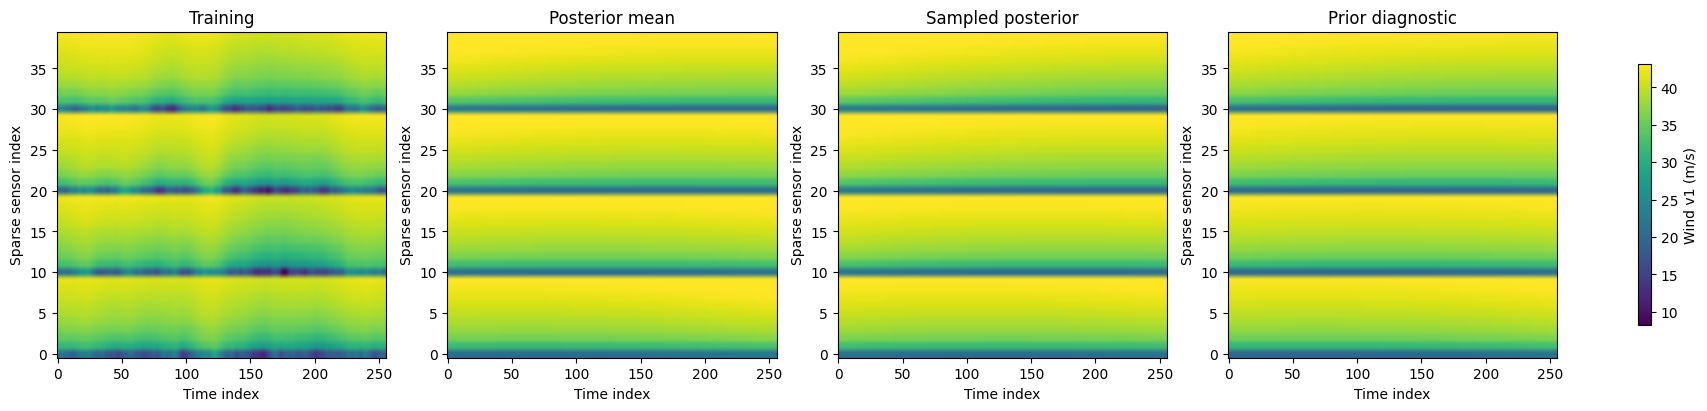


VAE STOCHASTIC POSTERIOR DIAGNOSIS

 Posterior mean
Temporal variance ratio: 0.042042723555531195
High-frequency PSD ratio: 0.04841722173063121
Between-field variance ratio: 2.2696520034815889e-10

 Sampled posterior
Temporal variance ratio: 0.059022463927420554
High-frequency PSD ratio: 0.07516325413112628
Between-field variance ratio: 0.01336074465755318

 Prior diagnostic
Temporal variance ratio: 0.05161556266127626
High-frequency PSD ratio: 0.06418816163261674
Between-field variance ratio: 0.03416096251271425

Saved: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/09_posterior_sampling_ablation.json
Saved: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/09_posterior_sampling_ablation.png


In [12]:

# CELL J — VAE posterior sampling ablation
# No retraining, no independent-test contamination

import json
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display

assert "ref" in globals()
assert "dataset" in globals()

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
OUT.mkdir(parents=True, exist_ok=True)

N = 16
rng = np.random.default_rng(20261029)
indices = rng.choice(
    len(dataset), size=N, replace=False
).tolist()

training = torch.stack(
    [dataset[i][0] for i in indices]
).float().numpy()

coords = dataset.points.float().cuda()
ref.eval()

generator = torch.Generator(
    device="cuda"
).manual_seed(20261029)

posterior_means = []
posterior_samples = []
prior_controls = []

with torch.inference_mode():
    for i in range(0, N, 2):
        src = torch.from_numpy(training[i:i+2]).cuda()
        mu, logvar = ref.encode(src)
        std = torch.exp(0.5 * logvar)

        sampled_z = mu + std * torch.randn(
            mu.shape, device="cuda", generator=generator
        )
        prior_z = torch.randn(
            mu.shape, device="cuda", generator=generator
        )

        for j in range(src.shape[0]):
            points = coords[None]

            posterior_means.append(
                ref.decode(mu[j:j+1], points)
                .reshape(40, 256).cpu().numpy()
            )
            posterior_samples.append(
                ref.decode(sampled_z[j:j+1], points)
                .reshape(40, 256).cpu().numpy()
            )
            prior_controls.append(
                ref.decode(prior_z[j:j+1], points)
                .reshape(40, 256).cpu().numpy()
            )

groups = {
    "Training": training,
    "Posterior mean": np.stack(posterior_means),
    "Sampled posterior": np.stack(posterior_samples),
    "Prior diagnostic": np.stack(prior_controls)
}

def field_statistics(a):
    a = np.asarray(a, dtype=np.float64)
    centered = a - a.mean(axis=-1, keepdims=True)
    psd = np.abs(np.fft.rfft(centered, axis=-1))**2

    return {
        "temporal_variance": float(
            a.var(axis=-1).mean()
        ),
        "between_field_variance": float(
            a.var(axis=0).mean()
        ),
        "high_frequency_psd": float(
            psd[:, :, 17:65].mean()
        ),
        "all_finite": bool(np.isfinite(a).all())
    }

stats = {
    name: field_statistics(arr)
    for name, arr in groups.items()
}

metrics = [
    "temporal_variance",
    "between_field_variance",
    "high_frequency_psd"
]

ratios = {
    name: {
        metric: value[metric] /
        max(stats["Training"][metric], 1e-20)
        for metric in metrics
    }
    for name, value in stats.items()
    if name != "Training"
}

report = {
    "evaluation": "Training-only diagnostic, not independent test",
    "num_fields": N,
    "sampled_training_indices": indices,
    "statistics": stats,
    "ratios_against_training": ratios,
    "warning": (
        "Standard-normal latent samples are diagnostic only. "
        "Posterior-mean decoding and stochastic posterior "
        "sampling are different evaluation modes."
    )
}

json_path = OUT / "09_posterior_sampling_ablation.json"
json_path.write_text(
    json.dumps(report, indent=2, allow_nan=False)
)

# Common reference color scale for fair visual inspection.
fig, axes = plt.subplots(
    1, 4, figsize=(17, 4), constrained_layout=True
)

vmin = float(training[0].min() * 49 - 2)
vmax = float(training[0].max() * 49 - 2)

for ax, (name, fields) in zip(axes, groups.items()):
    image = ax.imshow(
        fields[0] * 49 - 2,
        origin="lower",
        aspect="auto",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )
    ax.set_title(name)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor index")

fig.colorbar(
    image, ax=axes, shrink=0.8, label="Wind v1 (m/s)"
)

fig_path = OUT / "09_posterior_sampling_ablation.png"
fig.savefig(fig_path, dpi=160)
display(fig)
plt.close(fig)

print("\n" + "=" * 60)
print("VAE STOCHASTIC POSTERIOR DIAGNOSIS")
print("=" * 60)

for name, values in ratios.items():
    print("\n", name)
    print("Temporal variance ratio:",
          values["temporal_variance"])
    print("High-frequency PSD ratio:",
          values["high_frequency_psd"])
    print("Between-field variance ratio:",
          values["between_field_variance"])

print("\nSaved:", json_path)
print("Saved:", fig_path)


In [13]:

# CELL K — Research decision summary

import json
from pathlib import Path

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

def load_report(name):
    p = OUT / name
    assert p.exists(), f"Missing {name}. Run Cells I and J first."
    return json.loads(p.read_text())

grad = load_report("08b_coherence_gradient_isolation.json")
posterior = load_report("09_posterior_sampling_ablation.json")

comparisons = grad["comparisons"]
ratios = posterior["ratios_against_training"]

print("=" * 65)
print("WIND VISION — RESEARCH DECISION SUMMARY")
print("=" * 65)

print("\n1. COHERENCE OPTIMIZATION")
for name, result in comparisons.items():
    print(
        name,
        "gradient error:",
        result["relative_gradient_difference"],
        "cosine:",
        result["gradient_cosine"]
    )

print("\n2. STOCHASTIC POSTERIOR FIDELITY")
for name, values in ratios.items():
    print("\n", name)
    print(
        "Temporal variance retained:",
        round(values["temporal_variance"] * 100, 3), "%"
    )
    print(
        "High-frequency PSD retained:",
        round(values["high_frequency_psd"] * 100, 3), "%"
    )
    print(
        "Between-field variance retained:",
        round(values["between_field_variance"] * 100, 3), "%"
    )

vectorized_error = comparisons[
    "vectorization_same_physicsnemo_model"
]["relative_gradient_difference"]

sampled_temporal = ratios[
    "Sampled posterior"
]["temporal_variance"]

print("\n3. NEXT RESEARCH PRIORITIES")

if vectorized_error > 1e-3:
    print(
        "PERFORMANCE: Investigate coherence target arithmetic "
        "and gradient sensitivity before benchmarking optimization."
    )
else:
    print(
        "PERFORMANCE: Gradient tolerance passed. "
        "Proceed to repeated matched timing comparisons."
    )

if sampled_temporal < 0.25:
    print(
        "FIDELITY: Stochastic posterior still retains less than "
        "25% of temporal variance. Prioritize VAE representation "
        "and training-objective investigation."
    )
else:
    print(
        "FIDELITY: Stochastic posterior retains at least 25% "
        "of temporal variance. Investigate the latent flow "
        "distribution and posterior sampling behavior."
    )

summary = {
    "coherence_gradient_relative_error": vectorized_error,
    "sampled_posterior_temporal_variance_ratio": sampled_temporal,
    "gradient_diagnostic": comparisons,
    "posterior_ratios": ratios,
    "evaluation_scope": "Training-only diagnostics"
}

destination = OUT / "10_research_decision_summary.json"
destination.write_text(json.dumps(summary, indent=2))

print("\nSaved:", destination)
print("RESEARCH SUMMARY COMPLETE")


WIND VISION — RESEARCH DECISION SUMMARY

1. COHERENCE OPTIMIZATION
framework_same_original_loss gradient error: 4.996972820929056e-10 cosine: 1.0
vectorization_same_physicsnemo_model gradient error: 0.00368296482816145 cosine: 0.9999932229704855
residual_only_vectorization gradient error: 0.03885348689805523 cosine: 0.999245197590212

2. STOCHASTIC POSTERIOR FIDELITY

 Posterior mean
Temporal variance retained: 4.204 %
High-frequency PSD retained: 4.842 %
Between-field variance retained: 0.0 %

 Sampled posterior
Temporal variance retained: 5.902 %
High-frequency PSD retained: 7.516 %
Between-field variance retained: 1.336 %

 Prior diagnostic
Temporal variance retained: 5.162 %
High-frequency PSD retained: 6.419 %
Between-field variance retained: 3.416 %

3. NEXT RESEARCH PRIORITIES
PERFORMANCE: Investigate coherence target arithmetic and gradient sensitivity before benchmarking optimization.
FIDELITY: Stochastic posterior still retains less than 25% of temporal variance. Prioritize V

In [14]:

# VERIFY RESEARCH VAULT RECOVERY
from pathlib import Path
import json

vault = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/"
    "physicsnemo_day1/_research_vault"
)

index = json.loads(
    (vault / "latest_index.json").read_text()
)

foreign = [
    name for name in index
    if name.startswith("drive/MyDrive/")
]

print("Indexed artifacts:", len(index))
print("Foreign index entries:", foreign)
print("Verified archive entries:", verify())
print("Automatic logger:", globals().get("_WV_AUDIT_HOOKS"))

assert not foreign, "Foreign references remain."
assert globals().get("_WV_AUDIT_HOOKS"), "Logger inactive."

print("\nPASS — RESEARCH ARCHIVE RECOVERED")
print("SAFE TO CONTINUE")


Indexed artifacts: 415
Foreign index entries: ['drive/MyDrive/Assignment3_GenerativeAI.ipynb', 'drive/MyDrive/CLFM_CLOUD_BUNDLE.zip', 'drive/MyDrive/CLFM_Research_Results/coherence_batch_size_precision.json', 'drive/MyDrive/CLFM_Research_Results/environment_initial.json', 'drive/MyDrive/CLFM_Research_Results/full_vae_loss_cuda_probe.json', 'drive/MyDrive/CLFM_Research_Results/physics_residual_numerical_parity.json', 'drive/MyDrive/CLFM_Research_Results/physics_residual_source_audit.json', 'drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/01_full_objective_parity.json', 'drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/02_same_l4_full_step_benchmark.json', 'drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/03_native_checkpoint_status.json', 'drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/04_flow_only_summary.json', 'drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/04_run_summary.json', 'drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/05_environment_provenance.j

NameError: name 'verify' is not defined

In [ ]:

# ============================================================
# WIND VISION — RESEARCH PROVENANCE GUARD
# Run once per Colab runtime, after mounting Google Drive.
#
# Automatically:
# - Records every subsequent executed cell and failure
# - Archives changed result files and model checkpoints
# - Preserves old versions using SHA-256 objects
# - Records environment, GPU, dependencies and Git commit
# - Provides a structured research notes function
# - Detects archival failures
#
# Does NOT modify NASA's reference repository.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import os
import shutil
import subprocess
import sys
import time
import uuid

ROOT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
assert ROOT.is_dir(), "Mount Google Drive first."

VAULT = ROOT / "_research_vault"
OBJECTS = VAULT / "objects"
CELLS = VAULT / "cells"

for directory in (OBJECTS, CELLS, VAULT / "sessions"):
    directory.mkdir(parents=True, exist_ok=True)

STATE_FILE = VAULT / "latest_index.json"
STATE = (
    json.loads(STATE_FILE.read_text())
    if STATE_FILE.exists() else {}
)

SESSION = (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "-" + uuid.uuid4().hex[:8]
)

def utc():
    return datetime.now(timezone.utc).isoformat()

def digest(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

def event(kind, **fields):
    row = dict(
        utc=utc(), session=SESSION,
        kind=kind, **fields
    )
    with (VAULT / "events.jsonl").open("a") as f:
        f.write(
            json.dumps(row, default=str, sort_keys=True)
            + "\n"
        )
        f.flush()

def write_json(path, obj):
    path = Path(path)
    temp = path.with_name(
        path.name + "." + uuid.uuid4().hex + ".tmp"
    )
    try:
        temp.write_text(
            json.dumps(obj, default=str, indent=2)
        )
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)

def archive_file(source, name):
    source = Path(source)
    stat = source.stat()
    previous = STATE.get(name)

    if previous and (
        previous["size"], previous["mtime_ns"]
    ) == (stat.st_size, stat.st_mtime_ns):
        saved = (
            OBJECTS / previous["sha256"][:2]
            / previous["sha256"]
        )
        if saved.is_file():
            return None

    sha = digest(source)
    saved = OBJECTS / sha[:2] / sha
    saved.parent.mkdir(parents=True, exist_ok=True)

    if not saved.exists():
        temp = saved.with_name(
            saved.name + "." + uuid.uuid4().hex + ".tmp"
        )
        try:
            shutil.copyfile(source, temp)
            assert digest(temp) == sha, (
                f"Source changed during archiving: {source}"
            )
            os.replace(temp, saved)
        finally:
            temp.unlink(missing_ok=True)

    STATE[name] = dict(
        sha256=sha,
        size=stat.st_size,
        mtime_ns=stat.st_mtime_ns,
        object=str(saved.relative_to(VAULT))
    )

    return dict(
        name=name,
        sha256=sha,
        size=stat.st_size
    )

def snapshot(reason="manual"):
    changed, errors = [], []

    files = [
        (f, str(f.relative_to(ROOT)))
        for f in ROOT.rglob("*")
        if f.is_file()
        and VAULT not in f.parents
        and f.suffix not in (
            ".tmp", ".pyc", ".partial"
        )
    ]

    # Include the live Python implementation in /content.
    live = Path(
        "/content/wind_vision_physicsnemo_day1.py"
    )

    if live.exists():
        files.append((
            live,
            "runtime_source/wind_vision_physicsnemo_day1.py"
        ))

    for path, name in sorted(
        files, key=lambda pair: pair[1]
    ):
        try:
            item = archive_file(path, name)
            if item:
                changed.append(item)
        except Exception as exc:
            errors.append({
                "path": name,
                "error": str(exc)
            })

    write_json(STATE_FILE, STATE)
    event(
        "artifact_snapshot",
        reason=reason,
        changed=changed,
        errors=errors
    )

    if errors:
        raise RuntimeError(
            "RESEARCH ARCHIVE FAILED: " + str(errors)
        )

    return changed

def verify():
    bad = []

    for name, item in STATE.items():
        obj = (
            OBJECTS / item["sha256"][:2]
            / item["sha256"]
        )
        if (
            not obj.is_file()
            or digest(obj) != item["sha256"]
        ):
            bad.append(name)

    if bad:
        raise RuntimeError(
            "CORRUPT OR MISSING ARCHIVE OBJECTS: "
            + str(bad)
        )

    return len(STATE)

def note(
    title, question, methods,
    evidence, findings, limitations, decision
):
    fields = dict(
        title=title,
        question=question,
        methods=methods,
        evidence=evidence,
        findings=findings,
        limitations=limitations,
        decision=decision
    )

    event("research_note", **fields)

    with (VAULT / "lab_notebook.md").open("a") as f:
        f.write(
            f"\n## {utc()} — {title}\n\n"
        )
        for key, val in fields.items():
            f.write(f"**{key}:** {val}\n\n")

# ============================================================
# RECORD ENVIRONMENT AND DATA PROVENANCE
# ============================================================

meta = dict(
    utc=utc(),
    session=SESSION,
    python=sys.version,
    reference_repo=(
        "https://github.com/nasa/random_field_c-lfm"
    ),
    pinned_commit=(
        "921e666c8d6060ae13bfd901dcc7f74f819d0eea"
    ),
    checkpoint_expected_sha256=(
        "b78f9e00e623ccd3b72cc3f07751de5d7f27a930e95bcabe437aada14a62eb68"
    ),
    training_hdf5_expected_sha256=(
        "676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941"
    ),
    hash_scope=(
        "Expected input hashes from previously verified "
        "recovery. Large source dataset not rehashed here."
    ),
    holdout_policy=(
        "Training-only diagnostics; independent test "
        "data not supplied to this Colab runtime."
    )
)

for name in (
    "torch", "nvidia-physicsnemo",
    "lightning", "h5py", "numpy", "einops"
):
    try:
        meta["version_" + name] = (
            importlib.metadata.version(name)
        )
    except importlib.metadata.PackageNotFoundError:
        pass

try:
    import torch
    meta["cuda"] = torch.version.cuda
    meta["gpu"] = (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available() else None
    )
except Exception as exc:
    meta["gpu_probe_error"] = str(exc)

repo = Path("/content/nasa_clfm_reference")

if (repo / ".git").exists():
    meta["git_head"] = subprocess.check_output(
        ["git", "-C", str(repo), "rev-parse", "HEAD"],
        text=True
    ).strip()

    meta["git_dirty_files"] = subprocess.check_output(
        ["git", "-C", str(repo), "status", "--porcelain"],
        text=True
    )

write_json(
    VAULT / "sessions" / f"{SESSION}.json",
    meta
)

freeze_path = (
    VAULT / "sessions"
    / f"{SESSION}_pip_freeze.txt"
)

with freeze_path.open("w") as f:
    subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        stdout=f,
        check=True
    )

event("session_started", metadata=meta)

# ============================================================
# PRESERVE PREVIOUS IN-SESSION NOTEBOOK SOURCE
# ============================================================

ip = get_ipython()

for history_session, index, source in (
    ip.history_manager.get_range(
        output=False, raw=True
    )
):
    if not source.strip():
        continue

    filename = (
        CELLS
        / f"{SESSION}_past_{history_session}_{index}.py"
    )
    filename.write_text(source)

    archive_file(
        filename,
        "notebook_history/" + filename.name
    )

write_json(STATE_FILE, STATE)

# Avoid duplicate hooks if this setup is rerun.
old_hooks = globals().get("_WV_AUDIT_HOOKS")

if old_hooks:
    for hook_name, func in old_hooks:
        try:
            ip.events.unregister(hook_name, func)
        except ValueError:
            pass

running = {}

def before_cell(info):
    running["start"] = time.perf_counter()
    running["id"] = uuid.uuid4().hex[:12]

    try:
        path = (
            CELLS / f"{SESSION}_{running['id']}.py"
        )
        path.write_text(info.raw_cell)

        file_rec = archive_file(
            path,
            "executed_cells/" + path.name
        )

        event(
            "cell_started",
            cell_id=running["id"],
            source_sha256=file_rec["sha256"]
        )

    except Exception as exc:
        print(
            "CRITICAL RESEARCH LOGGING FAILURE "
            "(pre-cell):", exc,
            file=sys.stderr
        )

def after_cell(result):
    try:
        changed = snapshot("after_cell")
        exc = (
            result.error_before_exec
            or result.error_in_exec
        )

        event(
            "cell_finished",
            cell_id=running.get("id"),
            duration_s=(
                time.perf_counter()
                - running.get(
                    "start", time.perf_counter()
                )
            ),
            success=exc is None,
            exception=repr(exc) if exc else None,
            changed_artifacts=changed
        )

    except Exception as exc:
        print(
            "CRITICAL RESEARCH LOGGING FAILURE "
            "(post-cell):", exc,
            file=sys.stderr
        )

# ============================================================
# INITIAL AUDIT AND ACTIVATION
# ============================================================

# On reset, restore the previously patched source if missing.
live_script = Path(
    "/content/wind_vision_physicsnemo_day1.py"
)
saved_script = (
    ROOT / "wind_vision_physicsnemo_day1_patched.py"
)

if not live_script.exists() and saved_script.exists():
    shutil.copy2(saved_script, live_script)
    print("Restored patched runtime source from Drive.")

initial = snapshot("initial_import")

print("Initial artifact versions captured:", len(initial))
print("Vault objects verified:", verify())

ip.events.register("pre_run_cell", before_cell)
ip.events.register("post_run_cell", after_cell)

_WV_AUDIT_HOOKS = [
    ("pre_run_cell", before_cell),
    ("post_run_cell", after_cell)
]

print("=" * 60)
print("WIND VISION RESEARCH RECORDING ACTIVE")
print("=" * 60)
print("Session:", SESSION)
print("Vault:", VAULT)
print("Subsequent cell execution and artifact tracking: ON")
print("Source files and earlier artifact versions: PRESERVED")
print("No NASA reference files changed")


In [ ]:

# ============================================================
# CELL P1 v3 — WIND VISION RESEARCH PROVENANCE RECORDER
#
# COMPLETE REPLACEMENT for the old P1 cell.
#
# Fixes:
# - Unrelated Google Drive files entering the research index
# - Global ROOT / VAULT variables changing archive scope
# - Old invalid references breaking verification
# - Duplicate execution logging hooks
#
# Preserves:
# - Original index backup and audit report
# - Existing SHA-256 research objects and their versions
# - Experiment results, checkpoints, code and figures
# - Research journal and prior execution history
#
# No original files or archive objects are deleted.
# No NASA source files are modified.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import os
import shutil
import subprocess
import sys
import time
import uuid

RESEARCH_ROOT_V3 = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

assert RESEARCH_ROOT_V3.is_dir(), (
    "Mount Google Drive before running P1."
)
assert RESEARCH_ROOT_V3.name == "physicsnemo_day1"

_ip = get_ipython()
assert _ip is not None, "Run inside Colab."

# ------------------------------------------------------------
# 1. Disable previous research-recorder hooks
# ------------------------------------------------------------

for _event_name, _callback in globals().get(
    "_WV_AUDIT_HOOKS", []
):
    try:
        _ip.events.unregister(
            _event_name, _callback
        )
    except (ValueError, KeyError):
        pass

for _event_name in (
    "pre_run_cell", "post_run_cell"
):
    for _callback in list(
        _ip.events.callbacks.get(_event_name, [])
    ):
        if (
            getattr(_callback, "__name__", "")
            in (
                "before_cell",
                "after_cell",
                "wv_before_cell",
                "wv_after_cell"
            )
            and getattr(
                _callback, "__module__", ""
            ) == "__main__"
        ):
            try:
                _ip.events.unregister(
                    _event_name, _callback
                )
            except (ValueError, KeyError):
                pass


# ------------------------------------------------------------
# 2. Install scope-locked research recorder
# ------------------------------------------------------------

def _install_wind_recorder(root, ip):

    # Private root: other cells cannot redirect this by
    # reassigning global ROOT, OUT, VAULT, or STATE.
    root = root.resolve()

    vault = root / "_research_vault"
    objects = vault / "objects"
    cells = vault / "cells"
    sessions = vault / "sessions"

    for folder in (objects, cells, sessions):
        folder.mkdir(
            parents=True, exist_ok=True
        )

    index_path = vault / "latest_index.json"
    events_path = vault / "events.jsonl"

    session = (
        datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "-"
        + uuid.uuid4().hex[:8]
    )

    def stamp():
        return datetime.now(
            timezone.utc
        ).isoformat()

    def sha256(path):
        h = hashlib.sha256()

        with Path(path).open("rb") as stream:
            for chunk in iter(
                lambda: stream.read(
                    8 * 1024 * 1024
                ),
                b""
            ):
                h.update(chunk)

        return h.hexdigest()

    def save_json(path, data):
        path = Path(path)
        temp = path.with_name(
            path.name
            + "."
            + uuid.uuid4().hex
            + ".tmp"
        )

        try:
            temp.write_text(
                json.dumps(
                    data,
                    indent=2,
                    default=str
                )
            )
            os.replace(temp, path)
        finally:
            temp.unlink(missing_ok=True)

    def event(kind, **data):

        entry = {
            "utc": stamp(),
            "session": session,
            "kind": kind,
            **data
        }

        with events_path.open("a") as f:
            f.write(
                json.dumps(
                    entry,
                    default=str,
                    sort_keys=True
                ) + "\n"
            )
            f.flush()

    # --------------------------------------------------------
    # 3. Preserve exact historical index before repairing
    # --------------------------------------------------------

    original_bytes = (
        index_path.read_bytes()
        if index_path.exists()
        else b"{}"
    )

    old_index = json.loads(original_bytes)

    assert isinstance(old_index, dict), (
        "Unexpected research archive index format."
    )

    backup = sessions / (
        f"{session}_index_before_scope_repair.json"
    )

    backup.write_bytes(original_bytes)

    assert backup.read_bytes() == original_bytes

    # Incorrect entries came from scanning /content.
    # This prefix identifies legitimate Wind VISION files.
    prefix = (
        "drive/MyDrive/CLFM_Research_Results/"
        "physicsnemo_day1/"
    )

    active = {}
    foreign = []
    unresolved = []
    rekeyed = 0

    def valid_key(name):

        p = Path(name)

        return (
            bool(name)
            and bool(p.parts)
            and not p.is_absolute()
            and ".." not in p.parts
            and p.parts[0] != "_research_vault"
        )

    # --------------------------------------------------------
    # 4. Recover research-only archive references
    # --------------------------------------------------------

    for old_name, rec in old_index.items():

        if old_name.startswith(prefix):

            key = old_name[len(prefix):]
            rekeyed += 1

        elif (
            old_name.startswith("drive/")
            or old_name.startswith("/")
        ):

            foreign.append(old_name)
            continue

        else:
            key = old_name

        if (
            not valid_key(key)
            or not isinstance(rec, dict)
        ):
            unresolved.append({
                "key": old_name,
                "reason": "unsafe key or metadata"
            })
            continue

        digest = rec.get("sha256", "")

        if not (
            isinstance(digest, str)
            and len(digest) == 64
            and all(
                c in "0123456789abcdef"
                for c in digest
            )
        ):
            unresolved.append({
                "key": old_name,
                "reason": "invalid hash metadata"
            })
            continue

        obj = (
            objects
            / digest[:2]
            / digest
        )

        if (
            not obj.is_file()
            or sha256(obj) != digest
        ):
            unresolved.append({
                "key": old_name,
                "sha256": digest,
                "reason": (
                    "object missing or hash mismatch"
                )
            })
            continue

        # Preserve differing historical object versions.
        if key in active:

            if active[key]["sha256"] == digest:
                continue

            key = (
                f"legacy_versions/"
                f"{digest}/{key}"
            )

        active[key] = rec

    repair_report = sessions / (
        f"{session}_archive_scope_repair.json"
    )

    save_json(
        repair_report,
        {
            "utc": stamp(),
            "index_backup": str(backup),
            "old_entry_count": len(old_index),
            "foreign_keys_excluded": foreign,
            "research_keys_rekeyed": rekeyed,
            "unresolved_historical_entries":
                unresolved,
            "original_files_deleted": False,
            "archive_objects_deleted": False,
            "warning": (
                "Old out-of-scope objects remain in "
                "the vault. Do not publish this vault "
                "without a separate privacy audit."
            )
        }
    )

    save_json(index_path, active)

    # --------------------------------------------------------
    # 5. Content-addressed artifact storage
    # --------------------------------------------------------

    def archive(source, logical_key):

        source = Path(source)
        metadata = source.stat()
        previous = active.get(logical_key)

        if (
            previous
            and previous.get("size")
                == metadata.st_size
            and previous.get("mtime_ns")
                == metadata.st_mtime_ns
        ):

            obj = (
                objects
                / previous["sha256"][:2]
                / previous["sha256"]
            )

            if obj.is_file():
                return None

        digest = sha256(source)

        obj = objects / digest[:2] / digest
        obj.parent.mkdir(
            exist_ok=True,
            parents=True
        )

        if obj.exists():

            assert sha256(obj) == digest, (
                f"Archive object corrupted: {obj}"
            )

        else:

            temp = obj.with_name(
                obj.name
                + "."
                + uuid.uuid4().hex
                + ".tmp"
            )

            try:
                shutil.copyfile(source, temp)

                assert sha256(temp) == digest, (
                    "Source changed during copying: "
                    f"{source}"
                )

                os.replace(temp, obj)

            finally:
                temp.unlink(missing_ok=True)

        active[logical_key] = {
            "sha256": digest,
            "size": metadata.st_size,
            "mtime_ns": metadata.st_mtime_ns,
            "object": str(
                obj.relative_to(vault)
            )
        }

        return {
            "name": logical_key,
            "sha256": digest,
            "bytes": metadata.st_size
        }

    # --------------------------------------------------------
    # 6. Snapshot ONLY Wind VISION research files
    # --------------------------------------------------------

    def snapshot(reason="manual"):

        updated = []
        errors = []

        for source in root.rglob("*"):

            if (
                not source.is_file()
                or source.is_symlink()
                or vault in source.parents
                or source.suffix in (
                    ".pyc",
                    ".tmp",
                    ".partial"
                )
            ):
                continue

            try:

                logical_key = (
                    source.relative_to(root).as_posix()
                )

                entry = archive(
                    source,
                    logical_key
                )

                if entry:
                    updated.append(entry)

            except Exception as exc:
                errors.append({
                    "file": str(source),
                    "error": repr(exc)
                })

        # Capture the live research implementation.
        # This is the only additional source outside root.
        live = Path(
            "/content/"
            "wind_vision_physicsnemo_day1.py"
        )

        if live.is_file():

            try:
                entry = archive(
                    live,
                    "runtime_source/"
                    "wind_vision_physicsnemo_day1.py"
                )

                if entry:
                    updated.append(entry)

            except Exception as exc:
                errors.append({
                    "file": str(live),
                    "error": repr(exc)
                })

        save_json(index_path, active)

        event(
            "artifact_snapshot",
            reason=reason,
            changed=updated,
            errors=errors
        )

        if errors:
            raise RuntimeError(
                f"Snapshot errors: {errors}"
            )

        return updated

    # --------------------------------------------------------
    # 7. Verify active archive object integrity
    # --------------------------------------------------------

    def verify():

        errors = []

        for key, rec in active.items():

            digest = rec["sha256"]

            obj = (
                objects
                / digest[:2]
                / digest
            )

            if (
                not obj.is_file()
                or sha256(obj) != digest
            ):
                errors.append(key)

        if errors:
            raise RuntimeError(
                "Active research objects failed "
                "SHA256: "
                + str(errors)
            )

        return len(active)

    # --------------------------------------------------------
    # 8. Structured scientific laboratory journal
    # --------------------------------------------------------

    def note(
        title,
        question,
        methods,
        evidence,
        findings,
        limitations,
        decision
    ):

        data = dict(
            title=title,
            question=question,
            methods=methods,
            evidence=evidence,
            findings=findings,
            limitations=limitations,
            decision=decision
        )

        event("research_note", **data)

        with (
            vault / "lab_notebook.md"
        ).open("a") as f:

            f.write(
                f"\n## {stamp()} — {title}\n\n"
            )

            for key, value in data.items():
                f.write(
                    f"**{key}:** "
                    f"{json.dumps(value, default=str)}"
                    "\n\n"
                )

    # --------------------------------------------------------
    # 9. Recover patched implementation if necessary
    # --------------------------------------------------------

    live = Path(
        "/content/wind_vision_physicsnemo_day1.py"
    )

    stored = (
        root
        / "wind_vision_physicsnemo_day1_patched.py"
    )

    if (
        not live.exists()
        and stored.is_file()
    ):
        shutil.copy2(stored, live)

        print(
            "Restored patched PhysicsNeMo "
            "implementation from Drive."
        )

    # --------------------------------------------------------
    # 10. Verify restored archive and capture provenance
    # --------------------------------------------------------

    initial = snapshot(
        "p1_v3_scope_recovery"
    )

    verified = verify()

    provenance = {
        "utc": stamp(),
        "session": session,
        "python": sys.version,
        "research_root": str(root),
        "reference_commit_expected":
            "921e666c8d6060ae13bfd901dcc7f74f819d0eea"
    }

    try:
        import torch

        provenance.update(
            torch=torch.__version__,
            cuda=torch.version.cuda,
            gpu=(
                torch.cuda.get_device_name(0)
                if torch.cuda.is_available()
                else None
            )
        )

    except Exception as exc:
        provenance["gpu_probe_error"] = repr(exc)

    for package in (
        "nvidia-physicsnemo",
        "lightning",
        "numpy",
        "h5py",
        "einops"
    ):
        try:
            provenance[
                "package_" + package
            ] = importlib.metadata.version(package)

        except importlib.metadata.PackageNotFoundError:
            pass

    try:

        frozen = subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "freeze"
            ],
            capture_output=True,
            text=True,
            check=True
        )

        freeze_path = sessions / (
            f"{session}_pip_freeze.txt"
        )

        freeze_path.write_text(
            frozen.stdout
        )

    except Exception as exc:
        provenance["pip_freeze_error"] = repr(exc)

    repo = Path(
        "/content/nasa_clfm_reference"
    )

    if (repo / ".git").exists():

        status = subprocess.run(
            [
                "git",
                "-C", str(repo),
                "status",
                "--porcelain"
            ],
            capture_output=True,
            text=True
        )

        head = subprocess.run(
            [
                "git",
                "-C", str(repo),
                "rev-parse",
                "HEAD"
            ],
            capture_output=True,
            text=True
        )

        provenance.update(
            git_head=head.stdout.strip(),
            git_status=status.stdout
        )

    save_json(
        sessions / f"{session}_environment.json",
        provenance
    )

    event(
        "recorder_activated",
        verified=verified,
        unresolved_historical=len(unresolved),
        excluded_foreign=len(foreign)
    )

    # --------------------------------------------------------
    # 11. Automatically record future notebook cells
    # --------------------------------------------------------

    current = {}

    def wv_before_cell(info):

        current["id"] = uuid.uuid4().hex[:12]
        current["start"] = time.perf_counter()

        try:

            dest = cells / (
                f"{session}_{current['id']}.py"
            )

            dest.write_text(info.raw_cell)

            entry = archive(
                dest,
                f"executed_cells/{dest.name}"
            )

            save_json(index_path, active)

            event(
                "cell_started",
                cell_id=current["id"],
                source_sha256=(
                    entry["sha256"]
                    if entry
                    else sha256(dest)
                )
            )

        except Exception as exc:

            print(
                "CRITICAL research pre-cell "
                "logging failure:",
                repr(exc),
                file=sys.stderr
            )

    def wv_after_cell(result):

        failure = (
            result.error_before_exec
            or result.error_in_exec
        )

        try:

            changed = snapshot("after_cell")

            event(
                "cell_finished",
                cell_id=current.get("id"),
                elapsed_s=round(
                    time.perf_counter()
                    - current.get(
                        "start",
                        time.perf_counter()
                    ),
                    3
                ),
                success=failure is None,
                exception=(
                    repr(failure)
                    if failure
                    else None
                ),
                updated_files=len(changed)
            )

        except Exception as exc:

            print(
                "CRITICAL research post-cell "
                "logging failure:",
                repr(exc),
                file=sys.stderr
            )

    ip.events.register(
        "pre_run_cell",
        wv_before_cell
    )

    ip.events.register(
        "post_run_cell",
        wv_after_cell
    )

    return {
        "session": session,
        "root": root,
        "vault": vault,
        "snapshot": snapshot,
        "verify": verify,
        "note": note,
        "event": event,
        "hooks": [
            ("pre_run_cell", wv_before_cell),
            ("post_run_cell", wv_after_cell)
        ],
        "foreign": len(foreign),
        "rekeyed": rekeyed,
        "unresolved": len(unresolved),
        "verified": verified,
        "initial": len(initial),
        "repair_report": repair_report
    }


# ------------------------------------------------------------
# 12. Activate the repaired recorder
# ------------------------------------------------------------

_WV3 = _install_wind_recorder(
    RESEARCH_ROOT_V3,
    _ip
)

_WV_AUDIT_HOOKS = _WV3["hooks"]

verify = _WV3["verify"]
snapshot = _WV3["snapshot"]
note = _WV3["note"]
event = _WV3["event"]

print("\n" + "=" * 64)
print(
    "WIND VISION — SCOPE-LOCKED "
    "RESEARCH RECORDING ACTIVE"
)
print("=" * 64)

print(
    "Research folder:",
    _WV3["root"]
)

print(
    "Verified active entries:",
    _WV3["verified"]
)

print(
    "Old foreign entries excluded:",
    _WV3["foreign"]
)

print(
    "Research entries recovered/rekeyed:",
    _WV3["rekeyed"]
)

print(
    "Unresolved historical entries:",
    _WV3["unresolved"]
)

print(
    "Fresh artifact versions archived:",
    _WV3["initial"]
)

print(
    "Audit:",
    _WV3["repair_report"]
)

print("Automatic cell logging: ACTIVE")

if _WV3["unresolved"]:

    print(
        "WARNING: Historical archive has unresolved "
        "entries. See the audit report for details."
    )

else:

    print(
        "PASS — Active research archive "
        "integrity verified."
    )

print(
    "No user originals or historical vault "
    "objects were deleted."
)

# ------------------------------------------------------------
# 13. Continue research: inspect existing Cell O metrics
#     without retraining the VAE or consuming GPU time.
# ------------------------------------------------------------

run = (
    _WV3["root"]
    / "controlled_vae_ablations"
    / "20261029T193836Z-02073a"
    / "metrics.json"
)

if run.exists():

    result = json.loads(
        run.read_text()
    )

    print(
        "\nEXISTING CELL O RESULTS "
        "(NO RETRAINING):"
    )

    for arm in (
        "initial",
        "control",
        "temporal"
    ):

        if arm in result:

            print(
                arm,
                "reconstruction_mse=",
                result[arm].get(
                    "reconstruction_mse"
                ),
                "temporal_variance_ratio=",
                result[arm].get(
                    "ratios", {}
                ).get(
                    "temporal_variance"
                ),
                "high_psd_ratio=",
                result[arm].get(
                    "ratios", {}
                ).get(
                    "high_psd_17_64"
                )
            )


In [ ]:

# ============================================================
# WIND VISION — FORMAL RESEARCH RECORD
# Existing experimental findings and methodological controls
# ============================================================

from pathlib import Path
import json

required = [
    "01_full_objective_parity.json",
    "02_same_l4_full_step_benchmark.json",
    "03_native_checkpoint_status.json",
    "latent_flow/flow_demo_metrics.json",
    "latent_flow/paired_flow_state.pt",
    "latent_flow/unconditional_samples.pt",
    "latent_flow/short_flow_wind_demo.png",
    "07_training_only_fidelity_audit.json",
    "07_training_vs_posterior_vs_flow.png",
    "08_vectorized_coherence_validation.json",
    "08b_coherence_gradient_isolation.json",
    "09_posterior_sampling_ablation.json",
    "09_posterior_sampling_ablation.png",
    "10_research_decision_summary.json",
    "wind_vision_physicsnemo_day1_patched.py",
    "vae_integration_execution_v2.log",
    "latent_flow_execution_v2.log"
]

missing = [
    name for name in required
    if not (ROOT / name).is_file()
]

if missing:
    raise RuntimeError(
        "RESEARCH RECORD INCOMPLETE: " + str(missing)
    )

parity = json.loads(
    (ROOT / required[0]).read_text()
)
benchmark = json.loads(
    (ROOT / required[1]).read_text()
)
flow = json.loads(
    (ROOT / required[3]).read_text()
)
fidelity = json.loads(
    (ROOT / required[7]).read_text()
)
coherence = json.loads(
    (ROOT / required[9]).read_text()
)
posterior = json.loads(
    (ROOT / required[11]).read_text()
)

# Preserve a human-readable, evidence-linked methods record.
methods_path = ROOT / "RESEARCH_METHODS_AND_CONTROLS.md"

methods = """# Wind VISION — PhysicsNeMo Research Methods

## Research scope
NASA c-LFM synthetic wind-field generation using an
original constrained VAE and a paired latent-flow model.
Lead workstream: incorporation of NVIDIA PhysicsNeMo.

## Reference and provenance
NASA public repository:
https://github.com/nasa/random_field_c-lfm

Pinned commit:
921e666c8d6060ae13bfd901dcc7f74f819d0eea

PhysicsNeMo version: 2.2.2
Compute: NVIDIA L4, Google Colab Pro
Training data: synthetic wind HDF5
Sensor configuration: 40 sparse sensors
Temporal samples per field: 256
Latent dimension: 128

## Model and objective
The NASA model combines:
- 1D convolutional VAE encoder
- DeepONet branch/trunk function decoder
- Reconstruction MSE
- KL divergence
- Prescribed spectral coherence residual

The original objective is preserved in the integration.
Optimization experiments must be separately validated.

## Validation protocol
Numerical parity:
- Identical VAE initialization and state dictionaries
- Identical input data, precision and sampled noise
- Fixed random seeds for collocation
- Full loss and all parameter gradients
- Independent strict checks on checkpoint restoration

Benchmark:
- Same NVIDIA L4 GPU
- Matched model and workload
- Same optimizer, loss, precision and batch
- Warm-up and CUDA synchronization
- Record measured steps, median timing and memory
- Repeat and alternate order for publication-grade claims

## Current methodological limitations
The VAE checkpoint represents ten epochs, not a
complete 15,000-epoch reference reproduction.

The pilot benchmark is short, and does not establish
a general runtime advantage.

Flow matching used 32 optimizer steps and RK4-32,
not a converged model with the reference dopri5 solver.

Generation diagnostics use training data, not a
pristine independent test population.

The original upstream validation approach has used
test-named data. Future splits must prevent leakage.

The present model generates synthetic wind fields.
It is not validated operational AAM nowcasting.

No NVIDIA collaboration, endorsement, or paper
novelty claim is established by integration alone.

## Experimental evidence
See the numbered JSON reports, execution logs,
model checkpoints and PNG figures in this directory.

The _research_vault contains content-addressed
historical versions and execution provenance.

## Research integrity policy
Report failed experiments, negative results and
limitations alongside successful experiments.

Do not publish NASA-restricted data or materials
without applicable review and permission.

No independent-test or deployment claim without
appropriate holdout evaluation.
"""

methods_path.write_text(methods)

note(
    title="Native PhysicsNeMo VAE integration",
    question=(
        "Does PhysicsNeMo preserve the reference VAE "
        "objective and gradients?"
    ),
    methods=(
        "Strict weight transfer; matched L4 input, seed, "
        "precision; full reconstruction, KL and coherence "
        "backward comparison across 164 gradient tensors."
    ),
    evidence=[
        required[0],
        required[2],
        required[15]
    ],
    findings={
        "parity_pass": parity["parity_pass"],
        "relative_loss_difference":
            parity["relative_total_loss_difference"],
        "relative_gradient_difference":
            parity["relative_full_parameter_gradient_l2_difference"]
    },
    limitations=(
        "Deterministic tested batch only. Not a complete "
        "reference training reproduction."
    ),
    decision=(
        "Preserve as validated integration baseline."
    )
)

note(
    title="Initial same-GPU performance benchmark",
    question=(
        "Does native PhysicsNeMo integration achieve "
        "the target 2x speedup?"
    ),
    methods=(
        "Matched L4 full optimizer-step pilot; batch 4; "
        "short warm-up and measurement windows."
    ),
    evidence=[required[1], required[15]],
    findings={
        "speedup": benchmark[
            "speedup_pytorch_over_physicsnemo"
        ],
        "target_met": benchmark[
            "target_2x_met_in_this_pilot"
        ]
    },
    limitations=(
        "Short sequential benchmark. Performance advantage "
        "not statistically established; framework shares "
        "underlying PyTorch kernels."
    ),
    decision=(
        "Pursue independently validated computational "
        "optimizations and repeated benchmarks."
    )
)

note(
    title="Flow generation and fidelity ablation",
    question=(
        "Does the current c-LFM preserve temporal and "
        "between-field wind statistics?"
    ),
    methods=(
        "Paired latent flow pilot, training-only comparison, "
        "VAE posterior-mean, sampled-posterior and "
        "standard-normal latent diagnostics."
    ),
    evidence=[
        required[3], required[5], required[7],
        required[8], required[11], required[12]
    ],
    findings={
        "generated_finite": flow[
            "all_generated_finite"
        ],
        "generated_temporal_variance_ratio":
            fidelity["generation_to_training_ratios"][
                "temporal_variance_m_s2"
            ],
        "sampled_posterior_temporal_ratio":
            posterior["ratios_against_training"][
                "Sampled posterior"
            ]["temporal_variance"]
    },
    limitations=(
        "Training-only comparisons, small sample sizes, "
        "short flow training, undertrained VAE checkpoint."
    ),
    decision=(
        "Prioritize controlled VAE fidelity experiments "
        "over simply extending the short flow."
    )
)

note(
    title="Vectorized coherence optimization — failed parity",
    question=(
        "Can GPU vectorization accelerate the analytical "
        "constraint while preserving gradients?"
    ),
    methods=(
        "Original PyTorch constraint compared with "
        "GPU-vectorized analytical coherence target."
    ),
    evidence=[
        required[9],
        required[10]
    ],
    findings={
        "relative_loss_difference":
            coherence["relative_full_loss_difference"],
        "relative_gradient_difference":
            coherence["relative_gradient_difference"],
        "parity_pass": coherence["parity_pass"]
    },
    limitations=(
        "Gradient mismatch exceeds 0.1% tolerance. "
        "No valid speedup conclusion for this candidate."
    ),
    decision=(
        "Record negative result. Diagnose precision and "
        "operation order before performance evaluation."
    )
)

archived = snapshot("formal_methods_record")
verified_count = verify()

print("=" * 65)
print("RESEARCH DOCUMENTATION AUDIT")
print("=" * 65)
print("Required existing evidence files:", len(required))
print("Missing files:", len(missing))
print("New or changed artifacts archived:", len(archived))
print("Verified archive entries:", verified_count)
print("Methods document:", methods_path)
print("Research journal:", VAULT / "lab_notebook.md")
print("Provenance log:", VAULT / "events.jsonl")
print("=" * 65)
print("PASS — CURRENT RESEARCH RECORD ESTABLISHED")


In [ ]:

# CELL L — Analytical coherence target precision audit
# Automatically archived by the active research recorder.

import json
import torch
from pathlib import Path

assert all(
    name in globals()
    for name in ("original_wind", "original_loss", "nemo", "note")
), "Run Cells H and P1 in this runtime first."

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

torch.manual_seed(801)

n = original_loss.num_colloc
coordinates = nemo.grid.sample(2 * n)[:, :3]
x1, x2 = coordinates.chunk(2, dim=0)

freq = original_loss._freq_grid
freq_cpu = freq.detach().cpu()
a_cpu = x1.detach().cpu()
b_cpu = x2.detach().cpu()

# Original NASA target calculation
with torch.no_grad():
    reference = torch.stack([
        torch.tensor([
            original_wind.get_true_coherence(
                f, a_cpu[i], b_cpu[i]
            ) ** 2
            for f in freq_cpu
        ])
        for i in range(n)
    ]).to(device="cuda", dtype=torch.float64)

    coefficients = torch.tensor(
        original_wind.C,
        dtype=torch.float64,
        device="cuda"
    )

    a64 = x1.double()
    b64 = x2.double()

    # Current candidate: promote coordinates before subtraction
    distance64 = torch.linalg.vector_norm(
        (a64 - b64) * coefficients, dim=-1
    )

    # Alternative: subtract in float32 before promotion
    distance32 = torch.linalg.vector_norm(
        (x1 - x2).double() * coefficients,
        dim=-1
    )

    mean_a = (
        2.5 * original_wind.U_STAR *
        torch.log(a64[:, 2] / original_wind.Z_0)
    )
    mean_b = (
        2.5 * original_wind.U_STAR *
        torch.log(b64[:, 2] / original_wind.Z_0)
    )

    denom = mean_a.abs() + mean_b.abs()
    f64 = freq.double()

    target64 = torch.exp(
        -f64[None, :] * distance64[:, None]
        / denom[:, None]
    ).square()

    target32 = torch.exp(
        -f64[None, :] * distance32[:, None]
        / denom[:, None]
    ).square()

def compare_target(candidate):
    delta = (reference - candidate).abs()
    return {
        "max_absolute": float(delta.max()),
        "mean_absolute": float(delta.mean()),
        "rms": float(
            delta.square().mean().sqrt()
        ),
        "elements_over_1e-8": int(
            (delta > 1e-8).sum()
        ),
        "elements_over_1e-7": int(
            (delta > 1e-7).sum()
        ),
        "total_elements": delta.numel()
    }

report = {
    "experiment": "Analytical coherence target precision",
    "reference_commit":
        "921e666c8d6060ae13bfd901dcc7f74f819d0eea",
    "seed": 801,
    "collocation_pairs": n,
    "frequency_bins": len(freq),
    "original_vs_float64_subtraction":
        compare_target(target64),
    "original_vs_float32_subtraction":
        compare_target(target32),
    "limitations": [
        "Single fixed-collocation diagnostic",
        "Target agreement does not prove gradient parity",
        "Floating-point operation ordering may differ",
        "No acceleration benchmark performed"
    ]
}

path = OUT / "11_coherence_target_precision.json"
path.write_text(json.dumps(report, indent=2))

note(
    title="Coherence analytical target numerical precision",
    question=(
        "Does subtraction precision explain the "
        "vectorized analytical target discrepancy?"
    ),
    methods=(
        "Matched collocation coordinates and frequencies; "
        "original NASA target compared with float64-first "
        "and float32-first GPU calculations."
    ),
    evidence=[str(path)],
    findings=report,
    limitations=report["limitations"],
    decision=(
        "Use target discrepancies to guide further "
        "gradient-parity investigation. Do not claim "
        "numerical equivalence from forward loss alone."
    )
)

print("=" * 60)
print("COHERENCE TARGET PRECISION RESULTS")
print("=" * 60)
print(json.dumps(report, indent=2))
print("Saved:", path)
print("Research journal updated.")
print("Automatic archival active.")


In [ ]:

# CELL M — Same-graph coherence target sensitivity
# Requires Cells H and P1 in the current runtime.

import json
from pathlib import Path
import torch

required = (
    "nemo", "u", "eps", "original_loss",
    "original_wind", "note"
)
missing = [name for name in required if name not in globals()]
assert not missing, f"Missing variables: {missing}. Run H and P1 first."

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
OUT.mkdir(parents=True, exist_ok=True)

nemo.train()
assert u.shape[1:] == (40, 256)
assert next(nemo.parameters()).dtype == torch.float32

# ------------------------------------------------------------
# 1. Construct ONE shared computation graph.
# ------------------------------------------------------------

mu, logvar = nemo.encode(u)
z = mu + torch.exp(0.5 * logvar) * eps

n = original_loss.num_colloc
T = original_loss.T

torch.manual_seed(801)

space_coords = nemo.grid.sample(2 * n)[:, :3]
a, b = space_coords.chunk(2, dim=0)

space = space_coords.reshape(
    1, 2*n, 1, 3
).repeat(z.shape[0], 1, T, 1)

tgrid = original_loss._fixed_dense_t.to(
    device=z.device,
    dtype=space.dtype
).repeat(z.shape[0], 2*n, 1, 1)

pts = torch.cat(
    (space, tgrid), dim=-1
).reshape(z.shape[0], -1, nemo.grid.ndim)

wind = nemo.decode(
    z, pts
).reshape(z.shape[0], 2*n, T)

first, second = wind.chunk(2, dim=1)

coh = original_wind.v_coherence(
    first, second,
    nperseg=T,
    window=original_loss._hann_window
)

# ------------------------------------------------------------
# 2. Construct THREE analytical targets.
# ------------------------------------------------------------

freq = original_loss._freq_grid
acpu = a.detach().cpu()
bcpu = b.detach().cpu()
fcpu = freq.detach().cpu()

with torch.no_grad():

    # Exact original NASA CPU/NumPy target algorithm.
    nasa_target = torch.stack([
        torch.tensor([
            original_wind.get_true_coherence(
                f, acpu[i], bcpu[i]
            ) ** 2
            for f in fcpu
        ])
        for i in range(n)
    ]).to(coh.device)

    coeff = torch.tensor(
        original_wind.C,
        dtype=torch.float64,
        device=coh.device
    )

    a64, b64 = a.double(), b.double()

    vel_a = (
        2.5 * original_wind.U_STAR
        * torch.log(a64[:, 2] / original_wind.Z_0)
    )

    vel_b = (
        2.5 * original_wind.U_STAR
        * torch.log(b64[:, 2] / original_wind.Z_0)
    )

    denominator = vel_a.abs() + vel_b.abs()
    freq64 = freq.double()

    dist64 = torch.linalg.vector_norm(
        (a64 - b64) * coeff, dim=-1
    )

    dist32 = torch.linalg.vector_norm(
        (a - b).double() * coeff, dim=-1
    )

    target_doublefirst = torch.exp(
        -freq64[None] * dist64[:, None]
        / denominator[:, None]
    ).square()

    target_floatfirst = torch.exp(
        -freq64[None] * dist32[:, None]
        / denominator[:, None]
    ).square()

assert (
    nasa_target.shape
    == coh.shape
    == target_doublefirst.shape
)

assert torch.isfinite(coh).all()

targets = {
    "nasa_cpu_numpy": nasa_target,
    "gpu_double_first": target_doublefirst,
    "gpu_float32_subtract_first": target_floatfirst
}

# ------------------------------------------------------------
# 3. Compare residual gradients on SAME computation graph.
# ------------------------------------------------------------

parameters = [
    (name, p)
    for name, p in nemo.named_parameters()
    if p.requires_grad
]

results = {}

for index, (label, target) in enumerate(targets.items()):

    loss = (target - coh).square().mean()

    grads = torch.autograd.grad(
        loss,
        [p for _, p in parameters],
        retain_graph=index < len(targets)-1,
        allow_unused=True
    )

    results[label] = {
        "loss": float(loss.detach()),
        "grads": {
            name: g.detach().double().cpu()
            for (name, _), g in zip(parameters, grads)
            if g is not None
        }
    }

# ------------------------------------------------------------
# 4. Quantify absolute and relative gradient changes.
# ------------------------------------------------------------

def compare_to_nasa(label):

    reference = results["nasa_cpu_numpy"]["grads"]
    candidate = results[label]["grads"]

    assert reference.keys() == candidate.keys()

    base_sq = sum(
        v.square().sum().item()
        for v in reference.values()
    )

    delta_sq = sum(
        (reference[k] - candidate[k]).square().sum().item()
        for k in reference
    )

    candidate_sq = sum(
        v.square().sum().item()
        for v in candidate.values()
    )

    dot = sum(
        (reference[k] * candidate[k]).sum().item()
        for k in reference
    )

    per_parameter = sorted(
        [
            {
                "name": k,
                "baseline_l2": float(v.norm()),
                "difference_l2": float(
                    (v - candidate[k]).norm()
                )
            }
            for k, v in reference.items()
        ],
        key=lambda item: item["difference_l2"],
        reverse=True
    )

    return {
        "relative_residual_gradient_difference":
            delta_sq**0.5 / max(base_sq**0.5, 1e-12),

        "absolute_residual_gradient_difference_l2":
            delta_sq**0.5,

        "reference_residual_gradient_l2":
            base_sq**0.5,

        "gradient_cosine":
            dot / max(
                (base_sq * candidate_sq)**0.5,
                1e-24
            ),

        "target_max_abs_error": float(
            (nasa_target - targets[label]).abs().max()
        ),

        "per_parameter": per_parameter
    }

comparison = {
    label: compare_to_nasa(label)
    for label in list(targets)[1:]
}

# ------------------------------------------------------------
# 5. Persist results and methods.
# ------------------------------------------------------------

report = {
    "experiment":
        "same_graph_coherence_target_gradient_sensitivity",
    "scope":
        "Fixed VAE, latent noise, collocation coordinates "
        "and coherence graph",
    "gpu": torch.cuda.get_device_name(0),
    "batch_size": int(u.shape[0]),
    "dtype": str(coh.dtype),
    "collocation_seed": 801,
    "losses": {
        key: value["loss"]
        for key, value in results.items()
    },
    "comparisons": comparison,
    "limitations": [
        "Single fixed batch and collocation sample",
        "Residual-only gradient diagnosis",
        "Not a training benchmark",
        "No claim of gradient parity or acceleration"
    ]
}

path = OUT / "12_shared_graph_target_gradient_sensitivity.json"
path.write_text(
    json.dumps(report, indent=2, allow_nan=False)
)

print("=" * 60)
print("SHARED-GRAPH COHERENCE TARGET DIAGNOSTIC")
print("=" * 60)

print(
    "NASA residual:",
    report["losses"]["nasa_cpu_numpy"]
)

for name, item in comparison.items():

    print("\n", name)

    for key in (
        "target_max_abs_error",
        "reference_residual_gradient_l2",
        "absolute_residual_gradient_difference_l2",
        "relative_residual_gradient_difference",
        "gradient_cosine"
    ):
        print(" ", key, ":", item[key])

    print(
        "Top changed parameter:",
        item["per_parameter"][0]
    )

print("\nSaved:", path)

note(
    title="Same-graph coherence target gradient sensitivity",
    question=(
        "Are small analytical-target differences alone "
        "responsible for residual gradient divergence?"
    ),
    methods=(
        "Reuse a single decoded coherence computation "
        "graph and fixed collocation sample, "
        "changing only the prescribed target."
    ),
    evidence=[str(path)],
    findings={
        name: {
            k: v
            for k, v in item.items()
            if k != "per_parameter"
        }
        for name, item in comparison.items()
    },
    limitations=report["limitations"],
    decision=(
        "Determine whether exact NASA target arithmetic "
        "must be retained before performance optimization."
    )
)

print("Research journal updated.")
print("P1 archive will preserve the experiment.")
print("CELL M COMPLETE")


In [ ]:

# ============================================================
# CELL N — COHERENCE GRADIENT PRECISION DECOMPOSITION
#
# Separate:
# 1. Float32 versus float64 residual arithmetic
# 2. Differences in analytical target values
# 3. Whether casting the GPU target back to float32
#    restores acceptable gradient parity
#
# Uses ONE shared coherence computation graph.
# No training or benchmark claims.
# ============================================================

import torch
import json
from pathlib import Path

required_names = [
    "nemo", "u", "eps", "original_loss",
    "original_wind", "note"
]

missing = [
    name for name in required_names
    if name not in globals()
]

assert not missing, (
    f"Missing variables: {missing}. "
    "Run Cells H, M and P1 in this runtime."
)

OUT = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

torch.manual_seed(801)
torch.cuda.manual_seed_all(801)

nemo.train()

# ------------------------------------------------------------
# 1. Construct one common coherence computation graph
# ------------------------------------------------------------

mu, logvar = nemo.encode(u)

z = mu + torch.exp(0.5 * logvar) * eps

n = original_loss.num_colloc
T = original_loss.T
B = z.shape[0]

coordinates = nemo.grid.sample(2 * n)[:, :3]
a, b = coordinates.chunk(2, dim=0)

space = coordinates.reshape(
    1, 2*n, 1, 3
).repeat(B, 1, T, 1)

times = original_loss._fixed_dense_t.to(
    device=z.device,
    dtype=z.dtype
).repeat(B, 2*n, 1, 1)

points = torch.cat(
    [space, times], dim=-1
).reshape(B, -1, nemo.grid.ndim)

wind = nemo.decode(
    z, points
).reshape(B, 2*n, T)

y1, y2 = wind.chunk(2, dim=1)

coherence = original_wind.v_coherence(
    y1, y2,
    nperseg=T,
    window=original_loss._hann_window
)

assert coherence.dtype == torch.float32

# ------------------------------------------------------------
# 2. Reproduce NASA's exact original target computation
# ------------------------------------------------------------

freq = original_loss._freq_grid

acpu = a.detach().cpu()
bcpu = b.detach().cpu()
fcpu = freq.detach().cpu()

with torch.no_grad():

    nasa_target = torch.stack([
        torch.tensor([
            original_wind.get_true_coherence(
                f, acpu[i], bcpu[i]
            ) ** 2
            for f in fcpu
        ])
        for i in range(n)
    ]).to(coherence.device)

    assert nasa_target.dtype == torch.float32

    coefficients = torch.tensor(
        original_wind.C,
        device=coherence.device,
        dtype=torch.float64
    )

    a64 = a.double()
    b64 = b.double()

    va = (
        2.5 * original_wind.U_STAR
        * torch.log(
            a64[:, 2] / original_wind.Z_0
        )
    )

    vb = (
        2.5 * original_wind.U_STAR
        * torch.log(
            b64[:, 2] / original_wind.Z_0
        )
    )

    denominator = va.abs() + vb.abs()

    distance_double = torch.linalg.vector_norm(
        (a64 - b64) * coefficients,
        dim=-1
    )

    distance_floatfirst = torch.linalg.vector_norm(
        (a - b).double() * coefficients,
        dim=-1
    )

    frequencies = freq.double()

    gpu_double = torch.exp(
        -frequencies[None, :]
        * distance_double[:, None]
        / denominator[:, None]
    ).square()

    gpu_floatfirst = torch.exp(
        -frequencies[None, :]
        * distance_floatfirst[:, None]
        / denominator[:, None]
    ).square()

# ------------------------------------------------------------
# 3. Five precision-controlled comparisons
# ------------------------------------------------------------

variants = {
    "nasa_float32":
        nasa_target,

    "nasa_values_promoted_float64":
        nasa_target.double(),

    "gpu_double_target_float64":
        gpu_double,

    "gpu_double_target_cast_float32":
        gpu_double.float(),

    "gpu_floatfirst_target_cast_float32":
        gpu_floatfirst.float()
}

parameters = [
    (name, p)
    for name, p in nemo.named_parameters()
    if p.requires_grad
]

gradient_results = {}

for i, (name, target) in enumerate(variants.items()):

    residual = (
        target - coherence
    ).square().mean()

    gradients = torch.autograd.grad(
        residual,
        [p for _, p in parameters],
        retain_graph=i < len(variants)-1,
        allow_unused=True
    )

    gradient_results[name] = {
        "residual": float(residual.detach()),
        "residual_dtype": str(residual.dtype),
        "target_dtype": str(target.dtype),
        "gradients": {
            pname: g.detach().double().cpu()
            for (pname, _), g
            in zip(parameters, gradients)
            if g is not None
        }
    }

# ------------------------------------------------------------
# 4. Compare gradients using NASA float32 as reference
# ------------------------------------------------------------

def compare(reference_name, candidate_name):

    reference = gradient_results[reference_name]
    candidate = gradient_results[candidate_name]

    g0 = reference["gradients"]
    g1 = candidate["gradients"]

    assert g0.keys() == g1.keys()

    norm_sq = sum(
        v.square().sum().item()
        for v in g0.values()
    )

    diff_sq = sum(
        (g0[k] - g1[k]).square().sum().item()
        for k in g0
    )

    candidate_sq = sum(
        v.square().sum().item()
        for v in g1.values()
    )

    dot = sum(
        (g0[k] * g1[k]).sum().item()
        for k in g0
    )

    return {
        "relative_gradient_difference":
            diff_sq**0.5 / max(norm_sq**0.5, 1e-12),

        "absolute_gradient_difference_l2":
            diff_sq**0.5,

        "reference_gradient_l2":
            norm_sq**0.5,

        "gradient_cosine":
            dot / max(
                (norm_sq * candidate_sq)**0.5,
                1e-24
            ),

        "relative_residual_difference":
            abs(
                reference["residual"]
                - candidate["residual"]
            ) / max(abs(reference["residual"]), 1e-12)
    }

base_name = "nasa_float32"

comparisons = {
    name: compare(base_name, name)
    for name in list(variants)[1:]
}

# ------------------------------------------------------------
# 5. Save detailed results and research interpretation
# ------------------------------------------------------------

report = {
    "experiment":
        "coherence_gradient_precision_decomposition",

    "reference":
        "NASA original float32 residual",

    "model":
        "PhysicsNeMo VAE with fixed pretrained weights",

    "batch_size": int(B),
    "collocation_pairs": int(n),
    "time_samples": int(T),
    "seed": 801,

    "comparison_design": (
        "Same computation graph, parameters, decoded "
        "signals, coherence and collocation locations. "
        "Only analytical target values or their dtype change."
    ),

    "residuals": {
        name: {
            "value": result["residual"],
            "dtype": result["residual_dtype"],
            "target_dtype": result["target_dtype"]
        }
        for name, result in gradient_results.items()
    },

    "comparisons": comparisons,

    "target_max_abs_difference": {
        name: float(
            (nasa_target.double()
             - target.double()).abs().max()
        )
        for name, target in variants.items()
        if name != base_name
    },

    "gradient_tolerance": 1e-3,

    "limitations": [
        "Single fixed batch",
        "Single collocation realization",
        "Residual-only gradient comparison",
        "No model training",
        "No acceleration benchmark"
    ]
}

output_path = (
    OUT / "13_coherence_gradient_precision_decomposition.json"
)

output_path.write_text(
    json.dumps(
        report, indent=2, allow_nan=False
    )
)

print("=" * 65)
print("COHERENCE GRADIENT PRECISION DECOMPOSITION")
print("=" * 65)

print(
    "NASA baseline residual:",
    gradient_results[base_name]["residual"]
)

for name, result in comparisons.items():

    print("\n", name)

    print(
        " Relative gradient difference:",
        result["relative_gradient_difference"]
    )

    print(
        " Gradient cosine:",
        result["gradient_cosine"]
    )

    print(
        " Relative residual difference:",
        result["relative_residual_difference"]
    )

print("\nGRADIENT PARITY CHECKS")

for name, result in comparisons.items():

    passed = (
        result["relative_gradient_difference"]
        <= 1e-3
    )

    print(
        name, "PASS" if passed else "FAIL"
    )

note(
    title="Coherence residual precision decomposition",

    question=(
        "How much gradient discrepancy comes from "
        "loss arithmetic precision versus the "
        "analytical target's numerical values?"
    ),

    methods=report["comparison_design"],

    evidence=[str(output_path)],

    findings=comparisons,

    limitations=report["limitations"],

    decision=(
        "Retain the original NASA constraint as the "
        "validated baseline. Only consider an "
        "optimized target after gradient parity "
        "and repeated-seed verification."
    )
)

print("\nSaved:", output_path)
print("Research journal updated.")
print("CELL N COMPLETE")


In [ ]:

# CELL O — PAIRED VAE CONTINUATION TRAINING
# No installations. No changes to NASA reference source.
# Results are automatically archived by P1.

import sys, json, uuid, hashlib
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.nn import functional as F

sys.path.insert(0, "/content")
import wind_vision_physicsnemo_day1 as w

assert callable(globals().get("note")), "Run Cell P1 first."
assert torch.cuda.is_available(), "L4 GPU unavailable."

STEPS = 80
BS = 4
LR = 5e-4
TEMP_WEIGHT = 1e-3
SEED = 20261029

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
RUN = OUT / "controlled_vae_ablations" / (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "-" + uuid.uuid4().hex[:6]
)
RUN.mkdir(parents=True, exist_ok=False)

# ----------------------------------------------------------
# 1. Reference and data
# ----------------------------------------------------------

ckpt, train_file = w.assert_environment()
FVAE, _, _, _, _, DataCls, LossCls, _, kl_fn = (
    w.prepare_reference_imports()
)

dataset, physics_loss = w.make_loss_and_data(
    train_file, DataCls, LossCls
)
dataset.points = dataset.points.float()
physics_loss = physics_loss.cuda().float()

assert len(dataset.sensor_idx) == 40
assert len(dataset) >= STEPS * BS + 32

# Disjoint only for continuation training; the pretrained
# checkpoint may already have seen all these examples.
perm = np.random.default_rng(SEED).permutation(len(dataset))
train_ids = perm[:STEPS * BS].reshape(STEPS, BS)
probe_ids = perm[-32:]

# ----------------------------------------------------------
# 2. Identical PhysicsNeMo models and initialization
# ----------------------------------------------------------

torch.manual_seed(SEED)

trusted = FVAE.load_from_checkpoint(
    str(ckpt),
    map_location="cpu",
    weights_only=False
).float().eval()

assert trusted._encoder.input_layer.weight.shape[1] == 40

kwargs = dict(
    num_sensors=40,
    latent_dim=128,
    grid_low=trusted.grid.low.tolist(),
    grid_high=trusted.grid.high.tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
)

models, optimizers = {}, {}

for name in ("control", "temporal"):
    model = w.PhysicsNeMoWindVAE(**kwargs).cuda().float().train()
    model.load_state_dict(trusted.state_dict(), strict=True)
    models[name] = model
    optimizers[name] = torch.optim.Adam(
        model.parameters(), lr=LR
    )

assert all(
    torch.equal(a, b)
    for a, b in zip(
        models["control"].parameters(),
        models["temporal"].parameters()
    )
)

del trusted

# ----------------------------------------------------------
# 3. Save exact experimental configuration
# ----------------------------------------------------------

source_file = Path(w.__file__)
source_sha = hashlib.sha256(source_file.read_bytes()).hexdigest()

manifest = {
    "experiment": "paired_vae_continuation_temporal_derivative",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "source_script": str(source_file),
    "source_sha256": source_sha,
    "reference_commit": w.PINNED_GIT_SHA,
    "checkpoint_sha256": w.TRUSTED_CHECKPOINT_SHA,
    "gpu": torch.cuda.get_device_name(0),
    "steps_per_arm": STEPS,
    "batch_size": BS,
    "learning_rate": LR,
    "gradient_clip": 0.5,
    "seed": SEED,
    "temporal_weight": TEMP_WEIGHT,
    "original_weights": {
        "reconstruction": 1.0,
        "kl": 1e-6,
        "coherence": 0.01
    },
    "continuation_train_indices": train_ids.reshape(-1).tolist(),
    "diagnostic_indices": probe_ids.tolist(),
    "limitation": (
        "The diagnostic indices are excluded from this "
        "continuation run but not from the pretrained "
        "checkpoint's historical training population."
    )
}

(RUN / "manifest.json").write_text(
    json.dumps(manifest, indent=2)
)

# ----------------------------------------------------------
# 4. Define common fidelity evaluation
# ----------------------------------------------------------

def evaluate(model):
    model.eval()
    observed, predictions = [], []

    with torch.inference_mode():
        for j in range(0, len(probe_ids), BS):
            ids = probe_ids[j:j+BS]

            ut = torch.stack([
                dataset[int(i)][0] for i in ids
            ]).cuda().float()

            xy = dataset.points.cuda()[None].expand(
                len(ids), -1, -1
            )

            mu, _ = model.encode(ut)
            prediction = model.decode(
                mu, xy
            ).reshape_as(ut)

            observed.append(ut.cpu())
            predictions.append(prediction.cpu())

    obs = torch.cat(observed).numpy().astype(np.float64)
    pred = torch.cat(predictions).numpy().astype(np.float64)

    def statistics(a):
        centered = a - a.mean(-1, keepdims=True)
        psd = np.abs(np.fft.rfft(centered, axis=-1))**2

        return {
            "temporal_variance": float(
                a.var(axis=-1).mean()
            ),
            "between_field_variance": float(
                a.var(axis=0).mean()
            ),
            "high_psd_17_64": float(
                psd[..., 17:65].mean()
            )
        }

    reference = statistics(obs)
    generated = statistics(pred)

    metrics = {
        "reconstruction_mse": float(
            np.mean((pred - obs)**2)
        ),
        "temporal_derivative_mse": float(
            np.mean(
                (np.diff(pred, axis=-1)
                 - np.diff(obs, axis=-1))**2
            )
        ),
        "reference": reference,
        "prediction": generated,
        "ratios": {
            k: generated[k] / max(reference[k], 1e-20)
            for k in reference
        }
    }

    model.train()
    return metrics, obs, pred

initial, _, _ = evaluate(models["control"])
initial_variant, _, _ = evaluate(models["temporal"])

assert abs(
    initial["reconstruction_mse"]
    - initial_variant["reconstruction_mse"]
) < 1e-10

print("Identical initialization verified.")
print(
    "Initial temporal variance ratio:",
    initial["ratios"]["temporal_variance"]
)

# ----------------------------------------------------------
# 5. Matched continuation training
# ----------------------------------------------------------

history = []

noise_generator = torch.Generator(
    device="cuda"
).manual_seed(SEED + 17)

xy_cuda = dataset.points.cuda()[None].expand(
    BS, -1, -1
)

for step in range(STEPS):

    ids = train_ids[step]

    ut = torch.stack([
        dataset[int(i)][0] for i in ids
    ]).cuda().float()

    eps = torch.randn(
        BS, 128,
        generator=noise_generator,
        device="cuda"
    )

    colloc_seed = SEED + 4000 + step

    for name in ("control", "temporal"):

        model = models[name]
        optimizer = optimizers[name]
        optimizer.zero_grad(set_to_none=True)

        mu, logvar = model.encode(ut)
        z = mu + torch.exp(0.5 * logvar) * eps

        pred = model.decode(
            z, xy_cuda
        ).reshape_as(ut)

        rec = F.mse_loss(pred, ut)

        # First temporal differences
        delta_true = ut[..., 1:] - ut[..., :-1]
        delta_pred = pred[..., 1:] - pred[..., :-1]

        # Scale by observed temporal-difference energy.
        # Denominator is detached to avoid modifying target.
        temporal_relative = (
            F.mse_loss(delta_pred, delta_true)
            / delta_true.square().mean().detach().clamp_min(1e-6)
        )

        # Identical collocation seed for both models
        torch.manual_seed(colloc_seed)
        residual, _ = physics_loss.residual(model, z)

        kl = kl_fn(mu, logvar)

        native_objective = (
            rec + 1e-6 * kl + 0.01 * residual
        )

        objective = native_objective + (
            TEMP_WEIGHT * temporal_relative
            if name == "temporal" else 0.0
        )

        if not torch.isfinite(objective):
            raise FloatingPointError(
                f"Nonfinite objective: {name}, step {step}"
            )

        objective.backward()

        gradient_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(), 0.5
        )

        optimizer.step()

        history.append({
            "step": step + 1,
            "arm": name,
            "objective": float(objective.detach()),
            "native_objective": float(native_objective.detach()),
            "reconstruction": float(rec.detach()),
            "coherence_residual": float(residual.detach()),
            "kl_unweighted": float(kl.detach()),
            "relative_temporal_loss": float(
                temporal_relative.detach()
            ),
            "gradient_norm_before_clipping": float(
                gradient_norm.detach()
            )
        })

    if (step + 1) % 20 == 0:
        print(
            f"Completed paired step {step+1}/{STEPS}",
            flush=True
        )

        (RUN / "train_history.json").write_text(
            json.dumps(history, indent=2)
        )

        for name in models:
            torch.save({
                "state_dict": models[name].state_dict(),
                "optimizer": optimizers[name].state_dict(),
                "step": step + 1,
                "manifest_file": str(RUN / "manifest.json")
            }, RUN / f"{name}_step{step+1:03d}.pt")

# ----------------------------------------------------------
# 6. Compare initial, control and experimental model
# ----------------------------------------------------------

results = {
    "initial": initial,
    "initial_variant": initial_variant
}
plot_fields = {}

for name, model in models.items():
    metrics, observed, prediction = evaluate(model)
    results[name] = metrics
    plot_fields[name] = prediction[0]

results["evaluation_scope"] = (
    "Training-only diagnostic. Probe indices were excluded "
    "from this continuation, but not from earlier checkpoint "
    "training. No independent generalization claim."
)

(RUN / "metrics.json").write_text(
    json.dumps(results, indent=2)
)
(RUN / "train_history.json").write_text(
    json.dumps(history, indent=2)
)

# ----------------------------------------------------------
# 7. Save shared-scale wind-field visualization
# ----------------------------------------------------------

fields = [
    observed[0],
    plot_fields["control"],
    plot_fields["temporal"]
]

all_values = np.concatenate([
    field.ravel() for field in fields
]) * 49 - 2

vmin = float(all_values.min())
vmax = float(all_values.max())

fig, axes = plt.subplots(
    1, 3, figsize=(13, 4),
    constrained_layout=True
)

for ax, title, field in zip(
    axes,
    ["Training input", "Control after", "Temporal-loss after"],
    fields
):
    image = ax.imshow(
        field * 49 - 2,
        origin="lower",
        aspect="auto",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )
    ax.set_title(title)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor")

fig.colorbar(
    image, ax=axes,
    label="Wind v1 (m/s)",
    shrink=0.78
)

figure_path = RUN / "paired_fidelity.png"
fig.savefig(figure_path, dpi=150)
plt.show()
plt.close(fig)

# ----------------------------------------------------------
# 8. Print and document results
# ----------------------------------------------------------

summary = {
    name: {
        metric: round(value, 6)
        for metric, value in results[name]["ratios"].items()
    }
    for name in ("initial", "control", "temporal")
}

print("\n" + "=" * 65)
print("PAIRED VAE CONTINUATION RESULTS")
print("=" * 65)
print(json.dumps(summary, indent=2))

note(
    title="Paired VAE continuation with temporal derivative loss",
    question=(
        "Can temporal-derivative reconstruction improve "
        "wind variance relative to original-loss continuation?"
    ),
    methods=(
        f"Identical epoch-ten initialization, {STEPS} paired "
        f"steps, batch {BS}, Adam LR {LR}, identical noise and "
        f"collocation seeds, temporal coefficient {TEMP_WEIGHT}."
    ),
    evidence=[
        str(RUN / "manifest.json"),
        str(RUN / "metrics.json"),
        str(RUN / "train_history.json"),
        str(figure_path)
    ],
    findings=summary,
    limitations=[
        "Training-only evaluation population",
        "80-step pilot, not convergence",
        "No independent test or multiple-seed estimates",
        "Posterior-mean decoding only in this comparison"
    ],
    decision=(
        "Determine whether temporal augmentation improves "
        "fidelity over matched original-loss continuation "
        "without materially degrading reconstruction."
    )
)

print("\nSaved experiment:", RUN)
print("Research journal updated.")
print("Automatic archival will preserve experiment artifacts.")
print("CELL O COMPLETE")
